# Tech Challenge - Fase 1: Customer Churn

#### 1. Contexto & ML Canvas 

**Problema**: Uma operadora de telecomunicações está perdendo clientes em ritmo acelerado. A diretoria precisa de um modelo preditivo de churn que classifique clientes com risco de cancelamento.

**Objetivo**: Redução da taxa de churn trimestral, identificando clientes em risco de cancelamento com antecedência. 

**Métricas**: 
- Taxa de churn;
- Métricas superiores ao score já existente (Churn Score). (F1, ROC-AUC)

**Stakeholders**: equipe de dados/TI, CRM, atendimento. 

#### 2. Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import openpyxl
import missingno as msno
import math
from sklearn.model_selection import train_test_split
import joblib
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
import warnings
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
)

import optuna


#### 3. Ler dataset

##### Dicionário de Dados

7.043 observações com 33 variáveis:

* **CustomerID:** ID exclusivo que identifica cada cliente.
* **Count:** Valor utilizado em relatórios e dashboards para somar o número de clientes em um conjunto filtrado.
* **Country:** País de residência principal do cliente.
* **State:** Estado de residência principal do cliente.
* **City:** Cidade de residência principal do cliente.
* **Zip Code:** Código postal (CEP) da residência principal do cliente.
* **Lat Long:** Combinação de latitude e longitude da residência principal do cliente.
* **Latitude:** Latitude da residência principal do cliente.
* **Longitude:** Longitude da residência principal do cliente.
* **Gender:** Gênero do cliente (`Male`, `Female`).
* **Senior Citizen:** Indica se o cliente tem 65 anos ou mais (`Yes`, `No`).
* **Partner:** Indica se o cliente tem parceiro(a)/cônjuge (`Yes`, `No`).
* **Dependents:** Indica se o cliente reside com dependentes como filhos, pais ou avós (`Yes`, `No`).
* **Tenure Months:** Total de meses em que o cliente permaneceu ativo na empresa até o final do trimestre especificado.
* **Phone Service:** Indica se o cliente assina serviço de telefonia fixa com a empresa (`Yes`, `No`).
* **Multiple Lines:** Indica se o cliente assina múltiplas linhas telefônicas com a empresa (`Yes`, `No`).
* **Internet Service:** Provedor/tipo de serviço de internet contratado (`No`, `DSL`, `Fiber Optic`, `Cable`).
* **Online Security:** Indica contratação de serviço adicional de segurança online (`Yes`, `No`).
* **Online Backup:** Indica contratação de serviço adicional de backup em nuvem (`Yes`, `No`).
* **Device Protection:** Indica plano de proteção para equipamentos de internet (`Yes`, `No`).
* **Tech Support:** Indica assinatura de suporte técnico dedicado com tempo de espera reduzido (`Yes`, `No`).
* **Streaming TV:** Indica uso da conexão de internet para transmitir TV via parceiro terceiro sem custo extra (`Yes`, `No`).
* **Streaming Movies:** Indica uso da conexão de internet para transmitir filmes via parceiro terceiro sem custo extra (`Yes`, `No`).
* **Contract:** Tipo de contrato vigente do cliente (`Month-to-Month`, `One Year`, `Two Year`).
* **Paperless Billing:** Indica opção por fatura digital/sem papel (`Yes`, `No`).
* **Payment Method:** Método de pagamento da mensalidade (`Bank Withdrawal`, `Credit Card`, `Mailed Check`).
* **Monthly Charge:** Valor mensal total cobrado do cliente por todos os serviços ativos.
* **Total Charges:** Encargos totais acumulados calculados até o encerramento do trimestre.
* **Churn Label:** Indica cancelamento no trimestre (`Yes` = cancelou, `No` = permaneceu; correspondente direto de *Churn Value*).
* **Churn Value:** Variável alvo binária (`1` = cancelou no trimestre, `0` = permaneceu ativo; correspondente direto de *Churn Label*).
* **Churn Score:** Pontuação preditiva pré-existente (0 a 100) calculada via IBM SPSS Modeler. Quanto maior o score, maior a propensão histórica de cancelamento.
* **CLTV:** *Customer Lifetime Value* (Valor do Tempo de Vida do Cliente) calculado por modelos corporativos. Clientes com valores altos demandam monitoramento prioritário contra cancelamento.
* **Churn Reason:** Categoria ou razão específica declarada para encerramento do contrato.

---

**Fonte:**
IBM Business Analytics Community — [Telco Customer Churn](https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113)

In [2]:
# Fixação da seed para reprodutibilidade
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Carregamento do dataset oficial em data/raw/[cite: 2]
data_path = Path("../data/raw/Telco_customer_churn.xlsx")
df = pd.read_excel(data_path)

print(f"Volume de dados: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

Volume de dados: 7043 linhas e 33 colunas.


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [4]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [5]:
# Definição de ID e target

id_col = "CustomerID"
target_col = "Churn Value"


# Na base utilizada há o score de churn de um modelo já existente. Vamos usar esse score para um baseline de negócio, além do baseline técnico
business_baseline_score = "Churn Score"

# Separação entre numéricas e categóricas
num_features = df.select_dtypes(include=['int64', 'float64']).columns.drop([target_col, id_col], errors='ignore').tolist()
cat_features = df.select_dtypes(include=['object', 'category', 'str', 'string']).columns.drop([target_col, id_col], errors='ignore').tolist()

In [6]:
# Algumas variáveis com o tipo equivocado. Fazer mudança de tipo de variável.
remove_cat = ['Total Charges', 'Lat Long']

cat_features = [x for x in cat_features if x not in remove_cat]
num_features.extend(remove_cat)

In [7]:
num_features

['Count',
 'Zip Code',
 'Latitude',
 'Longitude',
 'Tenure Months',
 'Monthly Charges',
 'Churn Score',
 'CLTV',
 'Total Charges',
 'Lat Long']

In [8]:
cat_features

['Country',
 'State',
 'City',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Churn Label',
 'Churn Reason']

#### 4. Qualidade dos dados e limpeza estrutural

##### 4.1 Checagem de duplicatas

In [9]:
df["CustomerID"].is_unique

True

- `CustomerID` é único (7.043 clientes, uma linha por cliente): não há duplicatas;
- Como cada linha é um cliente distinto, o mesmo cliente não pode cair em treino e teste na divisão da seção 5.

##### 4.2 Checagem de nulos

- **`Churn Reason`** (5.174 nulos, 73,46%): o nulo é estrutural, pois o motivo só existe para quem cancelou. Além de não estar disponível no momento da previsão (*leakage*), a coluna é descartada na seção 4.3, então não há tratamento a fazer;
- **`Total Charges`** (11 campos em branco, 0,16%): chegou como texto (`object`) por causa dos brancos. A hipótese é que são clientes recém-chegados (`Tenure Months = 0`), ainda sem cobrança acumulada; a célula de correção confere isso. Os brancos viram `0.0` e a coluna passa a `float`;
- Preencher com a constante `0.0` é uma regra de negócio, não uma estatística aprendida dos dados, então não causa vazamento e pode ser feito antes do split. Qualquer imputação por média/mediana deve ir no `Pipeline` do Scikit-Learn, ajustada só no treino.

In [10]:
def check_missing_and_blank_values(df: pd.DataFrame) -> pd.DataFrame:
    """
    Identifica valores nulos (NaN/None) e strings vazias/espaços em branco
    em todas as colunas do DataFrame.
    """
    results = []

    for col in df.columns:
        # Contagem de NaNs padrão
        nan_count = df[col].isna().sum()
        
        # Contagem de espaços em branco ou strings vazias (apenas colunas de texto/objeto)
        blank_count = 0
        if df[col].dtype == "object" or pd.api.types.is_string_dtype(df[col]):
            blank_count = df[col].astype(str).str.strip().eq("").sum()
            # Ajusta caso o próprio NaN tenha virado string "nan" no cast
            actual_nans = df[col].isna().sum()
            blank_only_count = (df[col].astype(str).str.strip() == "").sum() - (df[col].isna() & (df[col].astype(str).str.strip() == "")).sum()
            blank_count = max(0, blank_only_count)
            
        total_missing = nan_count + blank_count
        pct_missing = (total_missing / len(df)) * 100

        results.append({
            "Coluna": col,
            "Tipo Atual": str(df[col].dtype),
            "Qtd NaN": nan_count,
            "Qtd Espaços em Branco": blank_count,
            "Total Incompletos": total_missing,
            "Percentual (%)": round(pct_missing, 2)
        })

    summary_df = pd.DataFrame(results)
    # Retorna apenas colunas com algum tipo de valor faltante ou em branco ordenado por percentual
    return summary_df[summary_df["Total Incompletos"] > 0].sort_values(
        by="Total Incompletos", ascending=False
    ).reset_index(drop=True)

In [11]:
df_missing = check_missing_and_blank_values(df)
print("Colunas com valores ausentes ou em branco:")
print(df_missing)

Colunas com valores ausentes ou em branco:
          Coluna Tipo Atual  Qtd NaN  Qtd Espaços em Branco  \
0   Churn Reason        str     5174                      0   
1  Total Charges     object        0                     11   

   Total Incompletos  Percentual (%)  
0               5174           73.46  
1                 11            0.16  


<Axes: >

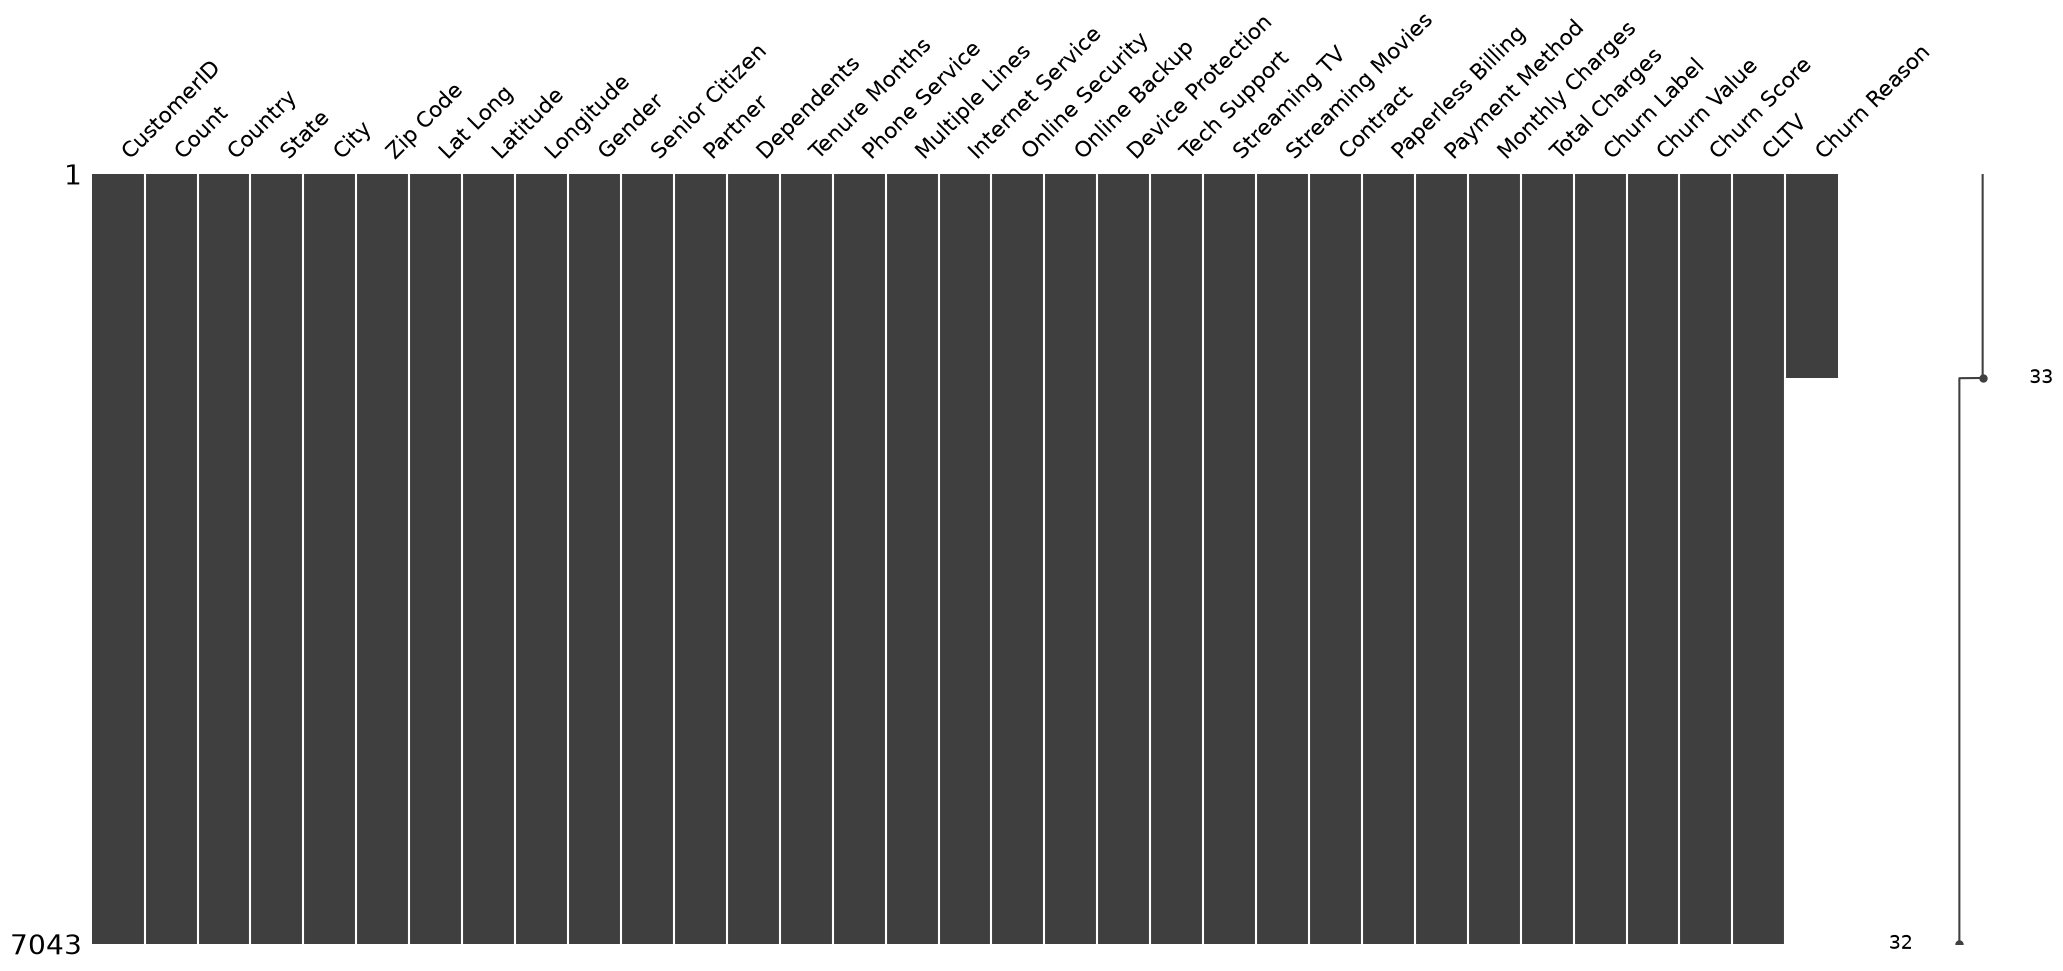

In [12]:
# Visualizar a matriz de valores ausentes
msno.matrix(df)


<Axes: >

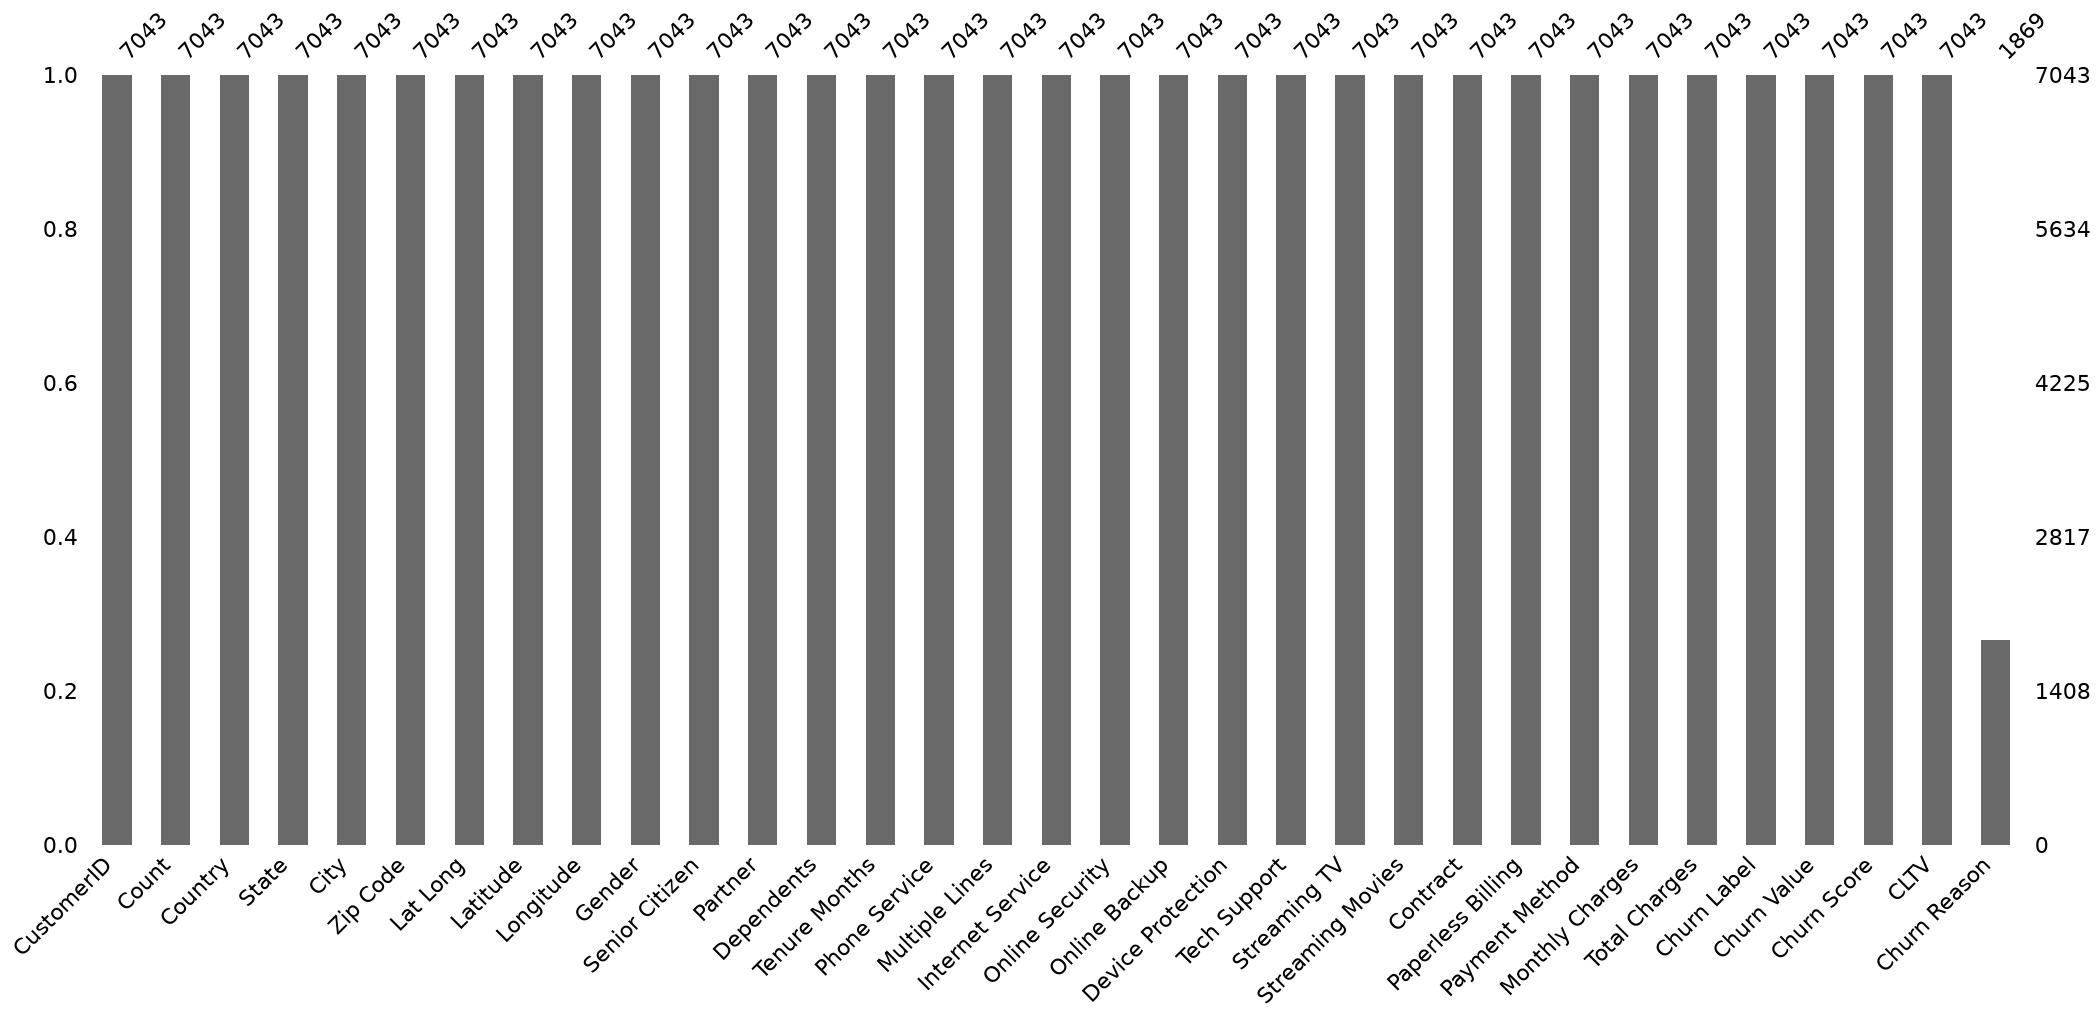

In [13]:
# Visualizar barras de completude
msno.bar(df)

In [14]:
# Correção dos valores em branco em Total Charges.
total_charges_raw = df['Total Charges'].astype(str).str.strip().replace("", np.nan)
blank_mask = total_charges_raw.isna()

# Confere a hipótese: os registros em branco são clientes recém-chegados (sem cobrança acumulada)
print(f"Registros em branco em Total Charges: {blank_mask.sum()}")
print(f"  - destes, com Tenure Months == 0: {(df.loc[blank_mask, 'Tenure Months'] == 0).sum()}")

total_charges_num = pd.to_numeric(total_charges_raw, errors='coerce')
# Garante que a conversão só gerou NaN onde havia branco (nenhum texto inválido escondido)
assert total_charges_num.isna().sum() == blank_mask.sum(), "Há valores não numéricos além dos brancos em Total Charges"

df['Total Charges'] = total_charges_num.fillna(0.0)

Registros em branco em Total Charges: 11
  - destes, com Tenure Months == 0: 11


In [15]:
df["Total Charges"].dtypes

dtype('float64')

##### 4.3 Limpeza de colunas

- **Valor constante (sem informação):** `Count`, `Country`, `State`;
- **Identificador / alta cardinalidade:** `CustomerID`, `City` (1.129 valores únicos), `Lat Long` (1.652);
- **Geográficas (granularidade muito fina ou redundantes entre si):** `Zip Code`, `Latitude`, `Longitude`;
- **Data leakage:** `Churn Label` (cópia textual do target), `Churn Reason` (só existe após o cancelamento) e `Churn Score` (saída de um modelo preditivo de churn já existente, IBM SPSS).

In [16]:
def inspect_and_clean_columns(
    df: pd.DataFrame, 
    cardinality_threshold: float = 0.5,
    max_unique_categories: int = 20,
    target_col: str = 'Churn Value'
) -> tuple[pd.DataFrame, dict]:
    """
    Inspeciona e limpa colunas com:
    - Valor constante (variância zero: 1 único valor em todas as linhas)
    - Alta cardinalidade (proporção excessiva de valores únicos em relação ao total ou > max_unique_categories)
    - Atributos geográficos e identificadores irrelevantes/vazados
    """
    total_rows = len(df)
    report = {
        'constant_cols': [],
        'high_cardinality_cols': [],
        'geo_and_leakage_cols': []
    }
    
    # 1. Identificar colunas constantes (1 único valor)
    for col in df.columns:
        if df[col].nunique(dropna=False) == 1:
            report['constant_cols'].append(col)
            
    # 2. Identificar alta cardinalidade em colunas categóricas/texto (exceto target)
    cat_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.drop(target_col, errors='ignore')
    for col in cat_cols:
        unique_count = df[col].nunique(dropna=True)
        unique_ratio = unique_count / total_rows
        if unique_ratio >= cardinality_threshold or unique_count > max_unique_categories:
            report['high_cardinality_cols'].append({
                'coluna': col,
                'valores_unicos': unique_count,
                'proporcao': round(unique_ratio, 4)
            })

    # 3. Lista padrão de atributos geográficos, metadados e data leakage no dataset IBM Telco
    geo_and_leakage_candidates = [
        'customerID', 'Count', 'Country', 'State', 'City', 
        'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label',
        'Churn Score', 'Churn Reason', 'Churn Category',
    ]
    report['geo_and_leakage_cols'] = [col for col in geo_and_leakage_candidates if col in df.columns]

    return report

In [17]:
# Executa o diagnóstico
report = inspect_and_clean_columns(df, target_col=target_col)

print("--- RELATÓRIO DE QUALIDADE DAS COLUNAS ---")
print(f"Colunas com valor constante (variância zero): {report['constant_cols']}")
print("Colunas de alta cardinalidade detectadas:")
for item in report['high_cardinality_cols']:
    print(f"  - {item['coluna']}: {item['valores_unicos']} valores únicos ({item['proporcao']*100:.1f}% das linhas)")

print(f"\nColunas geográficas, identificadores e leakage presentes: {report['geo_and_leakage_cols']}")

# Consolida colunas a serem descartadas
cols_to_drop = set(report['constant_cols']) | \
               {item['coluna'] for item in report['high_cardinality_cols']} | \
               set(report['geo_and_leakage_cols'])

# Mantém a integridade garantindo que o target nunca seja descartado por engano
cols_to_drop.discard(target_col)

# Aplica o descarte no DataFrame
df_clean = df.drop(columns=list(cols_to_drop)).copy()

print(f"\nTotal de colunas removidas: {len(cols_to_drop)}")
print(f"Colunas removidas: {sorted(list(cols_to_drop))}")
print(f"Dimensões do DataFrame após a limpeza: {df_clean.shape}")

--- RELATÓRIO DE QUALIDADE DAS COLUNAS ---
Colunas com valor constante (variância zero): ['Count', 'Country', 'State']
Colunas de alta cardinalidade detectadas:
  - CustomerID: 7043 valores únicos (100.0% das linhas)
  - City: 1129 valores únicos (16.0% das linhas)
  - Lat Long: 1652 valores únicos (23.5% das linhas)

Colunas geográficas, identificadores e leakage presentes: ['Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'Churn Reason']

Total de colunas removidas: 12
Colunas removidas: ['Churn Label', 'Churn Reason', 'Churn Score', 'City', 'Count', 'Country', 'CustomerID', 'Lat Long', 'Latitude', 'Longitude', 'State', 'Zip Code']
Dimensões do DataFrame após a limpeza: (7043, 21)


#### 5. Divisão treino/teste

Decisões:

- **80% treino / 20% teste**, com `random_state=42` (reprodutibilidade);
- **Estratificada pelo target** (`stratify=y`): como cerca de 26,5% dos clientes cancelaram, a estratificação mantém essa proporção nos dois conjuntos;
- **Sem conjunto de validação separado**: a seleção e a comparação de modelos (Etapa 2) serão feitas com validação cruzada estratificada **dentro do treino**;

In [18]:
TEST_SIZE = 0.20

# Separação entre features (X) e alvo (y). df_clean já não contém ID, leakage nem colunas geográficas.
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    stratify=y,                 # preserva a proporção de churn nos dois conjuntos
    random_state=RANDOM_STATE,  # reprodutibilidade
)

# Sanidade: nenhuma linha em comum entre treino e teste
assert X_train.index.intersection(X_test.index).empty

# Churn Score (modelo pré-existente da IBM) NÃO é feature (leakage), mas é guardado, alinhado pelo índice,
# como baseline de negócio para comparar com o modelo no mesmo conjunto de teste.
baseline_score_train = df.loc[X_train.index, business_baseline_score]
baseline_score_test = df.loc[X_test.index, business_baseline_score]

split_summary = pd.DataFrame({
    "Linhas": [len(X_train), len(X_test)],
    "Churn (n)": [int(y_train.sum()), int(y_test.sum())],
    "Churn (%)": [round(100 * y_train.mean(), 2), round(100 * y_test.mean(), 2)],
}, index=["Treino", "Teste"])

print(f"Total: {len(X)} linhas")
split_summary

Total: 7043 linhas


,Linhas,Churn (n),Churn (%)
Treino,5634,1495,26.54
Teste,1409,374,26.54


In [19]:
# Listas de features definidas a partir do TREINO (já sem colunas descartadas e sem o target).
# Substituem as listas provisórias da seção 3, que foram montadas sobre a base crua.
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

# Treino com o target: base de todas as análises da EDA (seção 6)
train_df = pd.concat([X_train, y_train], axis=1)

print(f"Numéricas ({len(num_features)}): {num_features}")
print(f"Categóricas ({len(cat_features)}): {cat_features}")

Numéricas (4): ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']
Categóricas (16): ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


**Conclusão:** a divisão gera cerca de 5.634 clientes de treino e 1.409 de teste, ambos com cerca de 26,5% de churn.

#### 6. EDA 
Todas as análises desta seção usam `train_df`. O conjunto de teste não é consultado.

##### 6.1 Análise univariada

- Há **desbalanceamento moderado** das classes: cerca de 26,5% dos clientes do treino cancelaram no trimestre (`Churn Value = 1`) contra cerca de 73,5% que permaneceram. A razão entre a classe minoritária e a majoritária é de aproximadamente 0,36. A estratificação mantém essa proporção no teste;
- Implicações para a modelagem:
    - acurácia isolada engana, pois um modelo que prevê "ninguém cancela" já acerta cerca de 73%;
    - usar métricas que olham para a classe positiva (recall, precisão, F1, PR-AUC), além de ROC-AUC e da matriz de confusão;
    - usar validação cruzada estratificada na otimização;
    - o desbalanceamento é pequeno o bastante para começar sem reamostragem; vale testar `class_weight='balanced'` nos modelos.

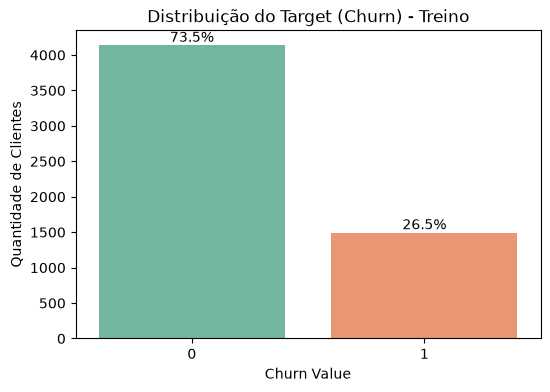

In [20]:
# Distribuição do target (treino)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=train_df, x=target_col, hue=target_col, palette='Set2', legend=False)
plt.title('Distribuição do Target (Churn) - Treino')
plt.ylabel('Quantidade de Clientes')

# Rótulos de porcentagem
total = len(train_df)
for p in ax.patches:
    if p.get_height() > 0:
        percentage = f'{100 * p.get_height() / total:.1f}%'
        ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom')
plt.show()

In [21]:
class_counts = train_df[target_col].value_counts().sort_index()
print(class_counts.to_string())
print(f"\nProporção de churn no treino: {class_counts[1] / class_counts.sum():.1%}")
print(f"Razão classe minoritária / majoritária: {class_counts.min() / class_counts.max():.2f}")

Churn Value
0    4139
1    1495

Proporção de churn no treino: 26.5%
Razão classe minoritária / majoritária: 0.36


In [22]:
# Configuração visual padrão para os gráficos
sns.set_theme(style="whitegrid")


# Função auxiliar para gerar grades dinâmicas de gráficos.
# Recebe o DataFrame explicitamente (train_df) para evitar usar a base completa por engano.
def plot_dynamic_grid(data, features, target_col, plot_type, title):
    if not features:
        return

    n_cols = 3
    n_rows = math.ceil(len(features) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4.5))
    fig.suptitle(title, fontsize=16, y=1.02)

    # Achata a matriz de eixos para facilitar a iteração, garantindo que seja iterável mesmo com 1 linha
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

    for i, col in enumerate(features):
        if plot_type == 'hist':
            sns.histplot(data=data, x=col, kde=True, ax=axes[i], color='teal', bins=30)
        elif plot_type == 'count':
            sns.countplot(data=data, x=col, hue=col, palette='muted', legend=False,
                          order=data[col].value_counts().index, ax=axes[i])
            axes[i].tick_params(axis='x', rotation=45)
        elif plot_type == 'box_bivariate':
            sns.boxplot(data=data, x=target_col, y=col, hue=target_col, palette='Set2',
                        legend=False, ax=axes[i])
        elif plot_type == 'count_bivariate':
            sns.countplot(data=data, x=col, hue=target_col, ax=axes[i], palette='Set2')
            axes[i].tick_params(axis='x', rotation=45)

        axes[i].set_title(col)

    # Esconde os quadros vazios se o número de features não for múltiplo de n_cols
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

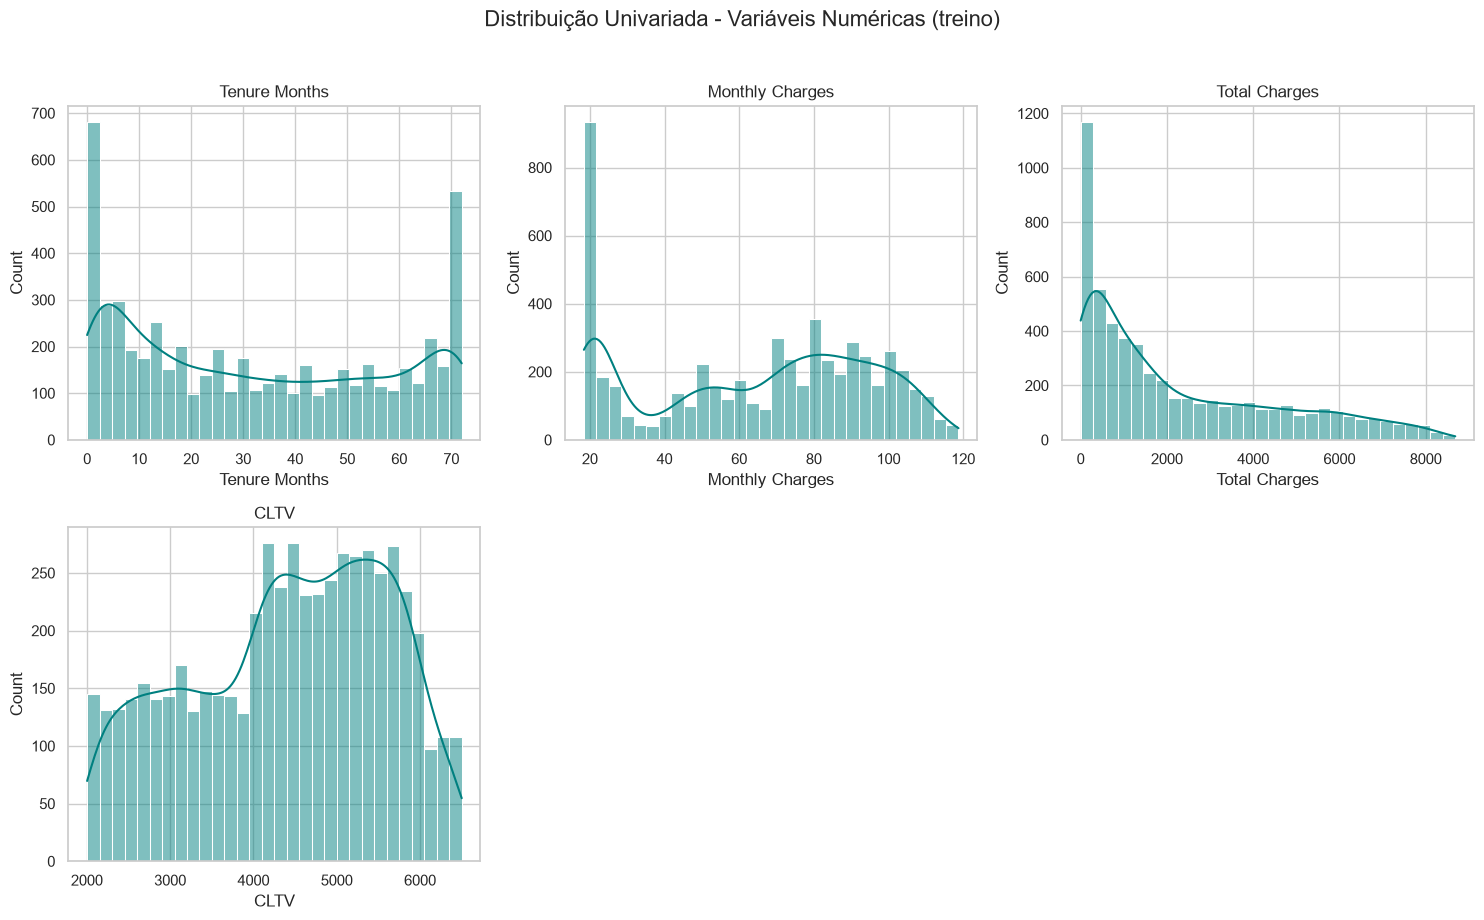

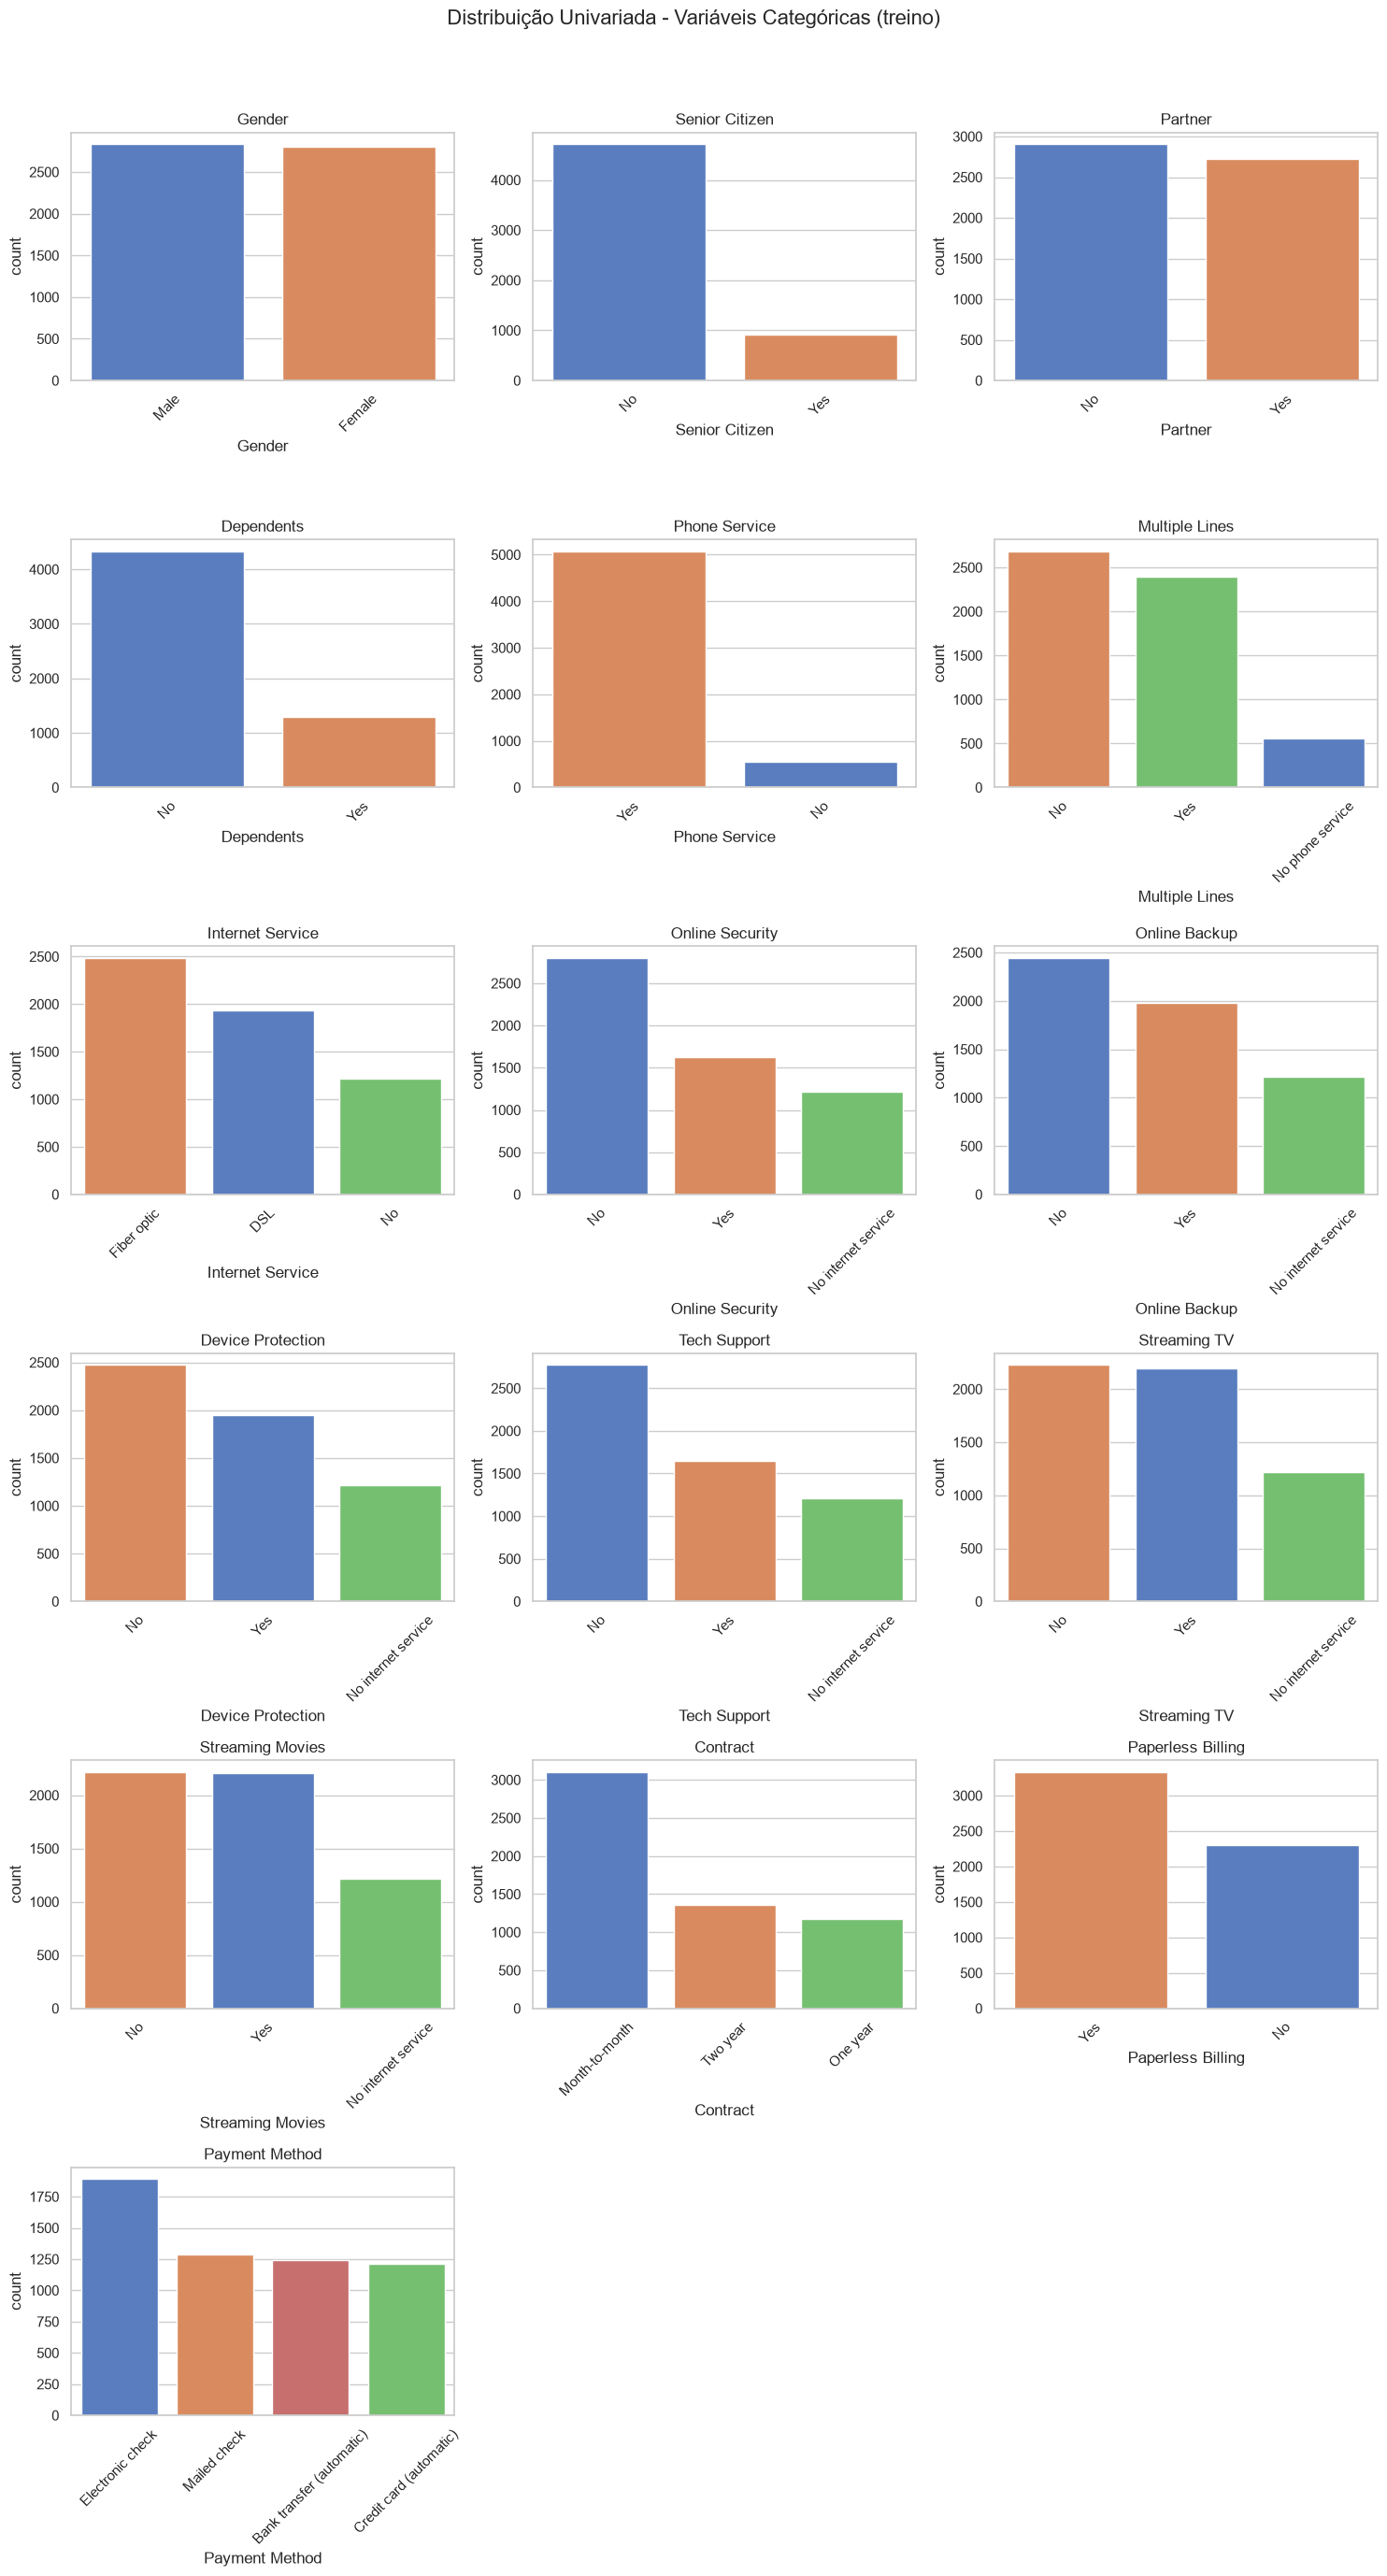

In [23]:
# Distribuição de TODAS as variáveis numéricas (treino)
plot_dynamic_grid(train_df, num_features, target_col, 'hist', 'Distribuição Univariada - Variáveis Numéricas (treino)')

# Distribuição de TODAS as variáveis categóricas (treino)
plot_dynamic_grid(train_df, cat_features, target_col, 'count', 'Distribuição Univariada - Variáveis Categóricas (treino)')

**Variáveis numéricas**

- `Tenure Months`: distribuição em "U", com picos nos clientes mais novos (0 a 1 mês) e nos mais antigos (72 meses, teto da janela de acompanhamento);
- `Monthly Charges`: grande concentração na faixa mais baixa (cerca de US$ 20, perfil de quem só tem telefone) e massa mais espalhada entre aproximadamente US$ 60 e 100;
- `Total Charges`: assimetria positiva forte (muitos clientes com cobrança acumulada baixa e cauda longa à direita), esperada por ser aproximadamente `Tenure Months` × `Monthly Charges`. Pode se beneficiar de transformação (ex.: log) em modelos lineares e na MLP;
- `CLTV`: faixa entre cerca de 2.000 e 6.500.

**Variáveis categóricas**

- `Gender` e `Partner` são equilibradas; `Senior Citizen` (maioria "No"), `Dependents` (maioria "No") e `Phone Service` (maioria "Yes") são bem desbalanceadas;
- Contrato `Month-to-month` é o mais frequente e `Electronic check` é a forma de pagamento mais comum;
- As colunas de serviços de internet (`Online Security`, `Online Backup`, `Device Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies`) trazem a categoria "No internet service", que é redundante com `Internet Service = No` (mesmos clientes). O mesmo vale para "No phone service" em `Multiple Lines` e `Phone Service = No`. O One-Hot Encoding lida com isso, mas essas dummies serão colineares.

##### 6.2 Análise de outliers

A inspeção pelo critério de Tukey (IQR), com limites calculados somente no treino não aponta outliers relevantes nas variáveis numéricas:

- **`Tenure Months`:** varia de 0 a 72 meses, bem dentro dos limites de Tukey. Os picos em 0–1 e 72 são comportamento real (clientes novos e janela máxima de acompanhamento), não erro;
- **`Monthly Charges`:** varia entre cerca de US$ 18 e US$ 119, dentro dos limites. A variação decorre da combinação de serviços contratados (internet, backup, segurança, streaming);
- **`Total Charges`:** assimetria positiva à direita, decorrente do acúmulo ao longo do tempo de contrato.
- **`CLTV`:** entre cerca de 2.000 e 6.500, sem valores extremos.

**Decisão:** não remover nem limitar registros por outlier. A assimetria de `Total Charges` será tratada, se necessário, por transformação/escala dentro do `Pipeline`, ajustada no treino.

--- RESUMO DE DETEÇÃO DE OUTLIERS (MÉTODO IQR) ---
       Variável  Q1 (25%)  Q3 (75%)     IQR  Limite Inferior  Limite Superior  Qtd Outliers  Outliers (%)
  Tenure Months      9.00     55.00   46.00           -60.00           124.00             0           0.0
Monthly Charges     35.66     90.00   54.34           -45.84           171.51             0           0.0
  Total Charges    402.98   3835.82 3432.85         -4746.30          8985.10             0           0.0
           CLTV   3470.25   5380.75 1910.50           604.50          8246.50             0           0.0


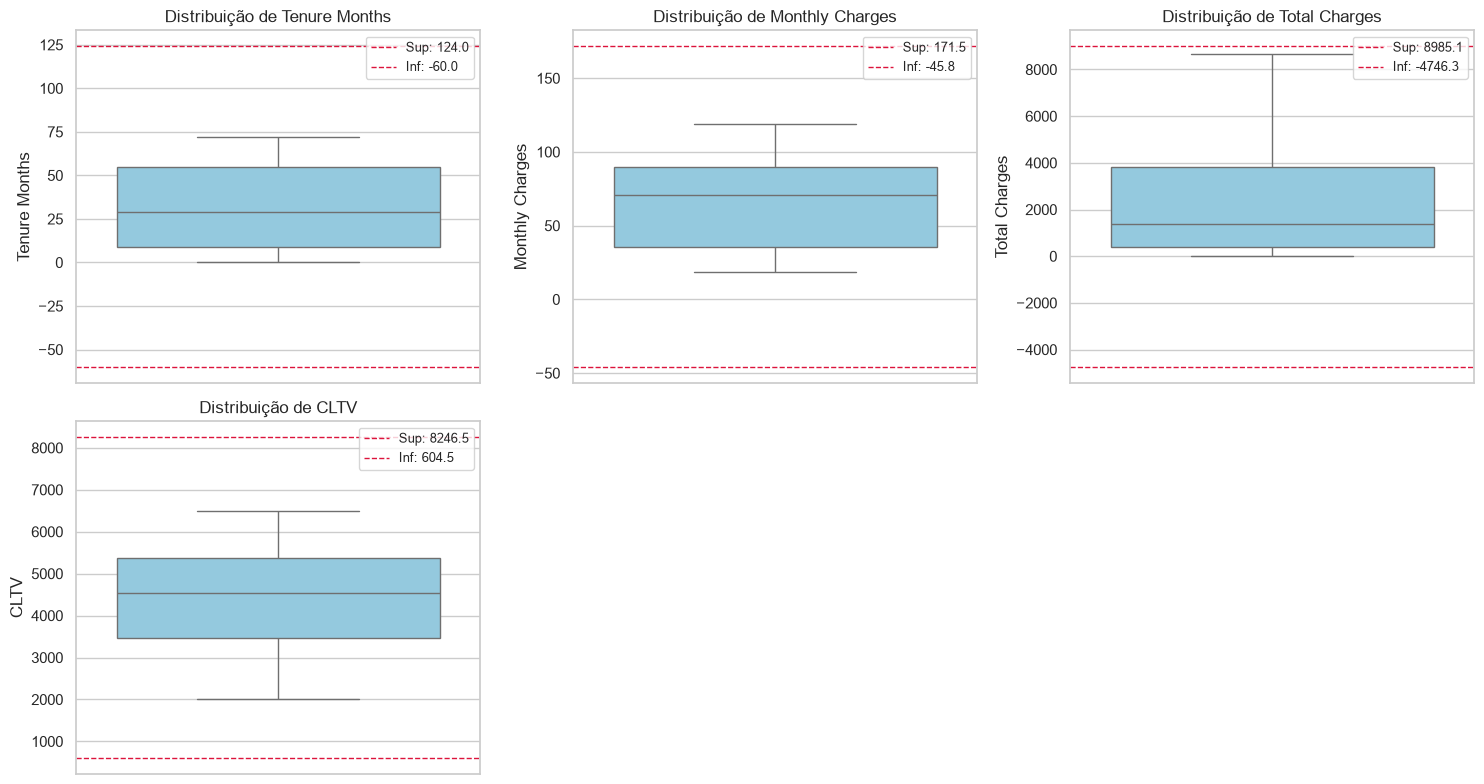

In [24]:
def detect_outliers_iqr(df: pd.DataFrame, features: list[str], threshold: float = 1.5) -> pd.DataFrame:
    """
    Calcula os limites inferior e superior com base no Intervalo Interquartil (IQR)
    e quantifica a presença de anomalias/outliers para cada variável numérica.
    """
    outlier_records = []
    total_rows = len(df)

    for col in features:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        
        lower_bound = q1 - (threshold * iqr)
        upper_bound = q3 + (threshold * iqr)
        
        # Identificação de registos fora das barreiras de Tukey
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
        outlier_count = len(outliers)
        outlier_pct = (outlier_count / total_rows) * 100
        
        outlier_records.append({
            'Variável': col,
            'Q1 (25%)': round(q1, 2),
            'Q3 (75%)': round(q3, 2),
            'IQR': round(iqr, 2),
            'Limite Inferior': round(lower_bound, 2),
            'Limite Superior': round(upper_bound, 2),
            'Qtd Outliers': outlier_count,
            'Outliers (%)': round(outlier_pct, 2)
        })

    summary_df = pd.DataFrame(outlier_records)
    return summary_df.sort_values(by='Qtd Outliers', ascending=False).reset_index(drop=True)


# 1. Diagnóstico numérico sobre as colunas numéricas do TREINO (os limites de Tukey vêm só do treino)
df_outliers_summary = detect_outliers_iqr(train_df, num_features)
print("--- RESUMO DE DETEÇÃO DE OUTLIERS (MÉTODO IQR) ---")
print(df_outliers_summary.to_string(index=False))


# 2. Visualização gráfica com Boxplots e linhas de corte
def plot_outlier_boxplots(df: pd.DataFrame, features: list[str], threshold: float = 1.5) -> None:
    """Plota boxplots detalhados com linhas tracejadas a representar os limites do IQR."""
    n_cols = 3
    n_rows = int(np.ceil(len(features) / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]
    
    for i, col in enumerate(features):
        ax = axes[i]
        sns.boxplot(data=df, y=col, ax=ax, color='skyblue', flierprops={'marker': 'o', 'markersize': 4, 'markerfacecolor': 'red'})
        
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - (threshold * iqr)
        upper_bound = q3 + (threshold * iqr)
        
        ax.axhline(upper_bound, color='crimson', linestyle='--', linewidth=1, label=f'Sup: {upper_bound:.1f}')
        ax.axhline(lower_bound, color='crimson', linestyle='--', linewidth=1, label=f'Inf: {lower_bound:.1f}')
        ax.set_title(f'Distribuição de {col}', fontsize=12)
        ax.legend(loc='upper right', fontsize=9)
        
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)
        
    plt.tight_layout()
    plt.show()

plot_outlier_boxplots(train_df, num_features)

##### 6.3 Análise bivariada

**Relação com o churn**

- **Tempo de casa:** quem cancela tem `Tenure Months` muito menor (mediana de poucos meses, contra cerca de 3 anos entre quem fica): o cancelamento se concentra no início do relacionamento. O `Total Charges` menor entre os churners é consequência direta disso;
- **Mensalidade:** `Monthly Charges` é um pouco maior entre quem cancela;
- **Contrato:** `Month-to-month` concentra a grande maioria dos cancelamentos; contratos de 1 e 2 anos têm churn baixo;
- **Internet e serviços adicionais:** churn maior em `Fiber optic`; quem não tem `Online Security`, `Online Backup`, `Device Protection` ou `Tech Support` cancela mais; clientes sem internet cancelam pouco;
- **Perfil e pagamento:** churn maior entre clientes sem `Partner`, sem `Dependents`, `Senior Citizen` e com `Paperless Billing`; entre as formas de pagamento destaca-se `Electronic check`;
- **Sem sinal aparente:** `Gender` e `Phone Service` têm proporções de churn muito parecidas entre as categorias; `Multiple Lines` e `Streaming TV/Movies` mostram diferença pequena.

**Correlação (numéricas)**

- `Tenure Months` é a numérica mais associada ao target (correlação negativa moderada, em torno de −0,35); `Monthly Charges` tem correlação positiva fraca (cerca de +0,2) e `Total Charges` negativa fraca (cerca de −0,2).
- **Multicolinearidade:** `Tenure Months` e `Total Charges` são fortemente correlacionadas (cerca de 0,8) e `Monthly Charges` e `Total Charges` moderadamente (cerca de 0,65), o que é esperado pela construção de `Total Charges`. Isso afeta sobretudo a Regressão Logística (coeficientes instáveis); a decisão de remover ou transformar fica para a seção 7, com base no treino.


--- ANÁLISE BIVARIADA (treino) ---


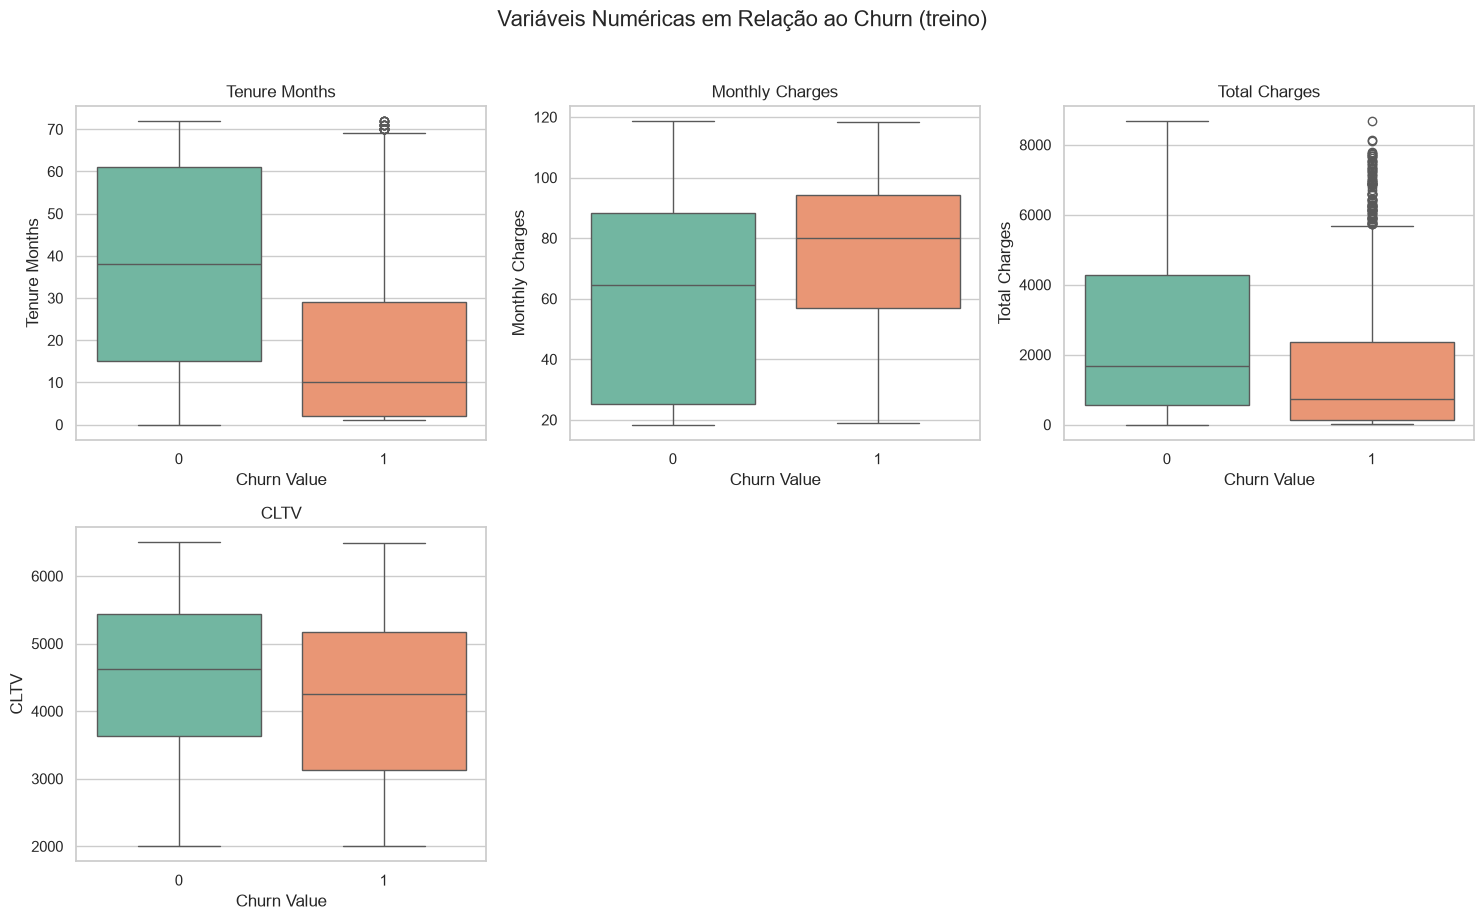

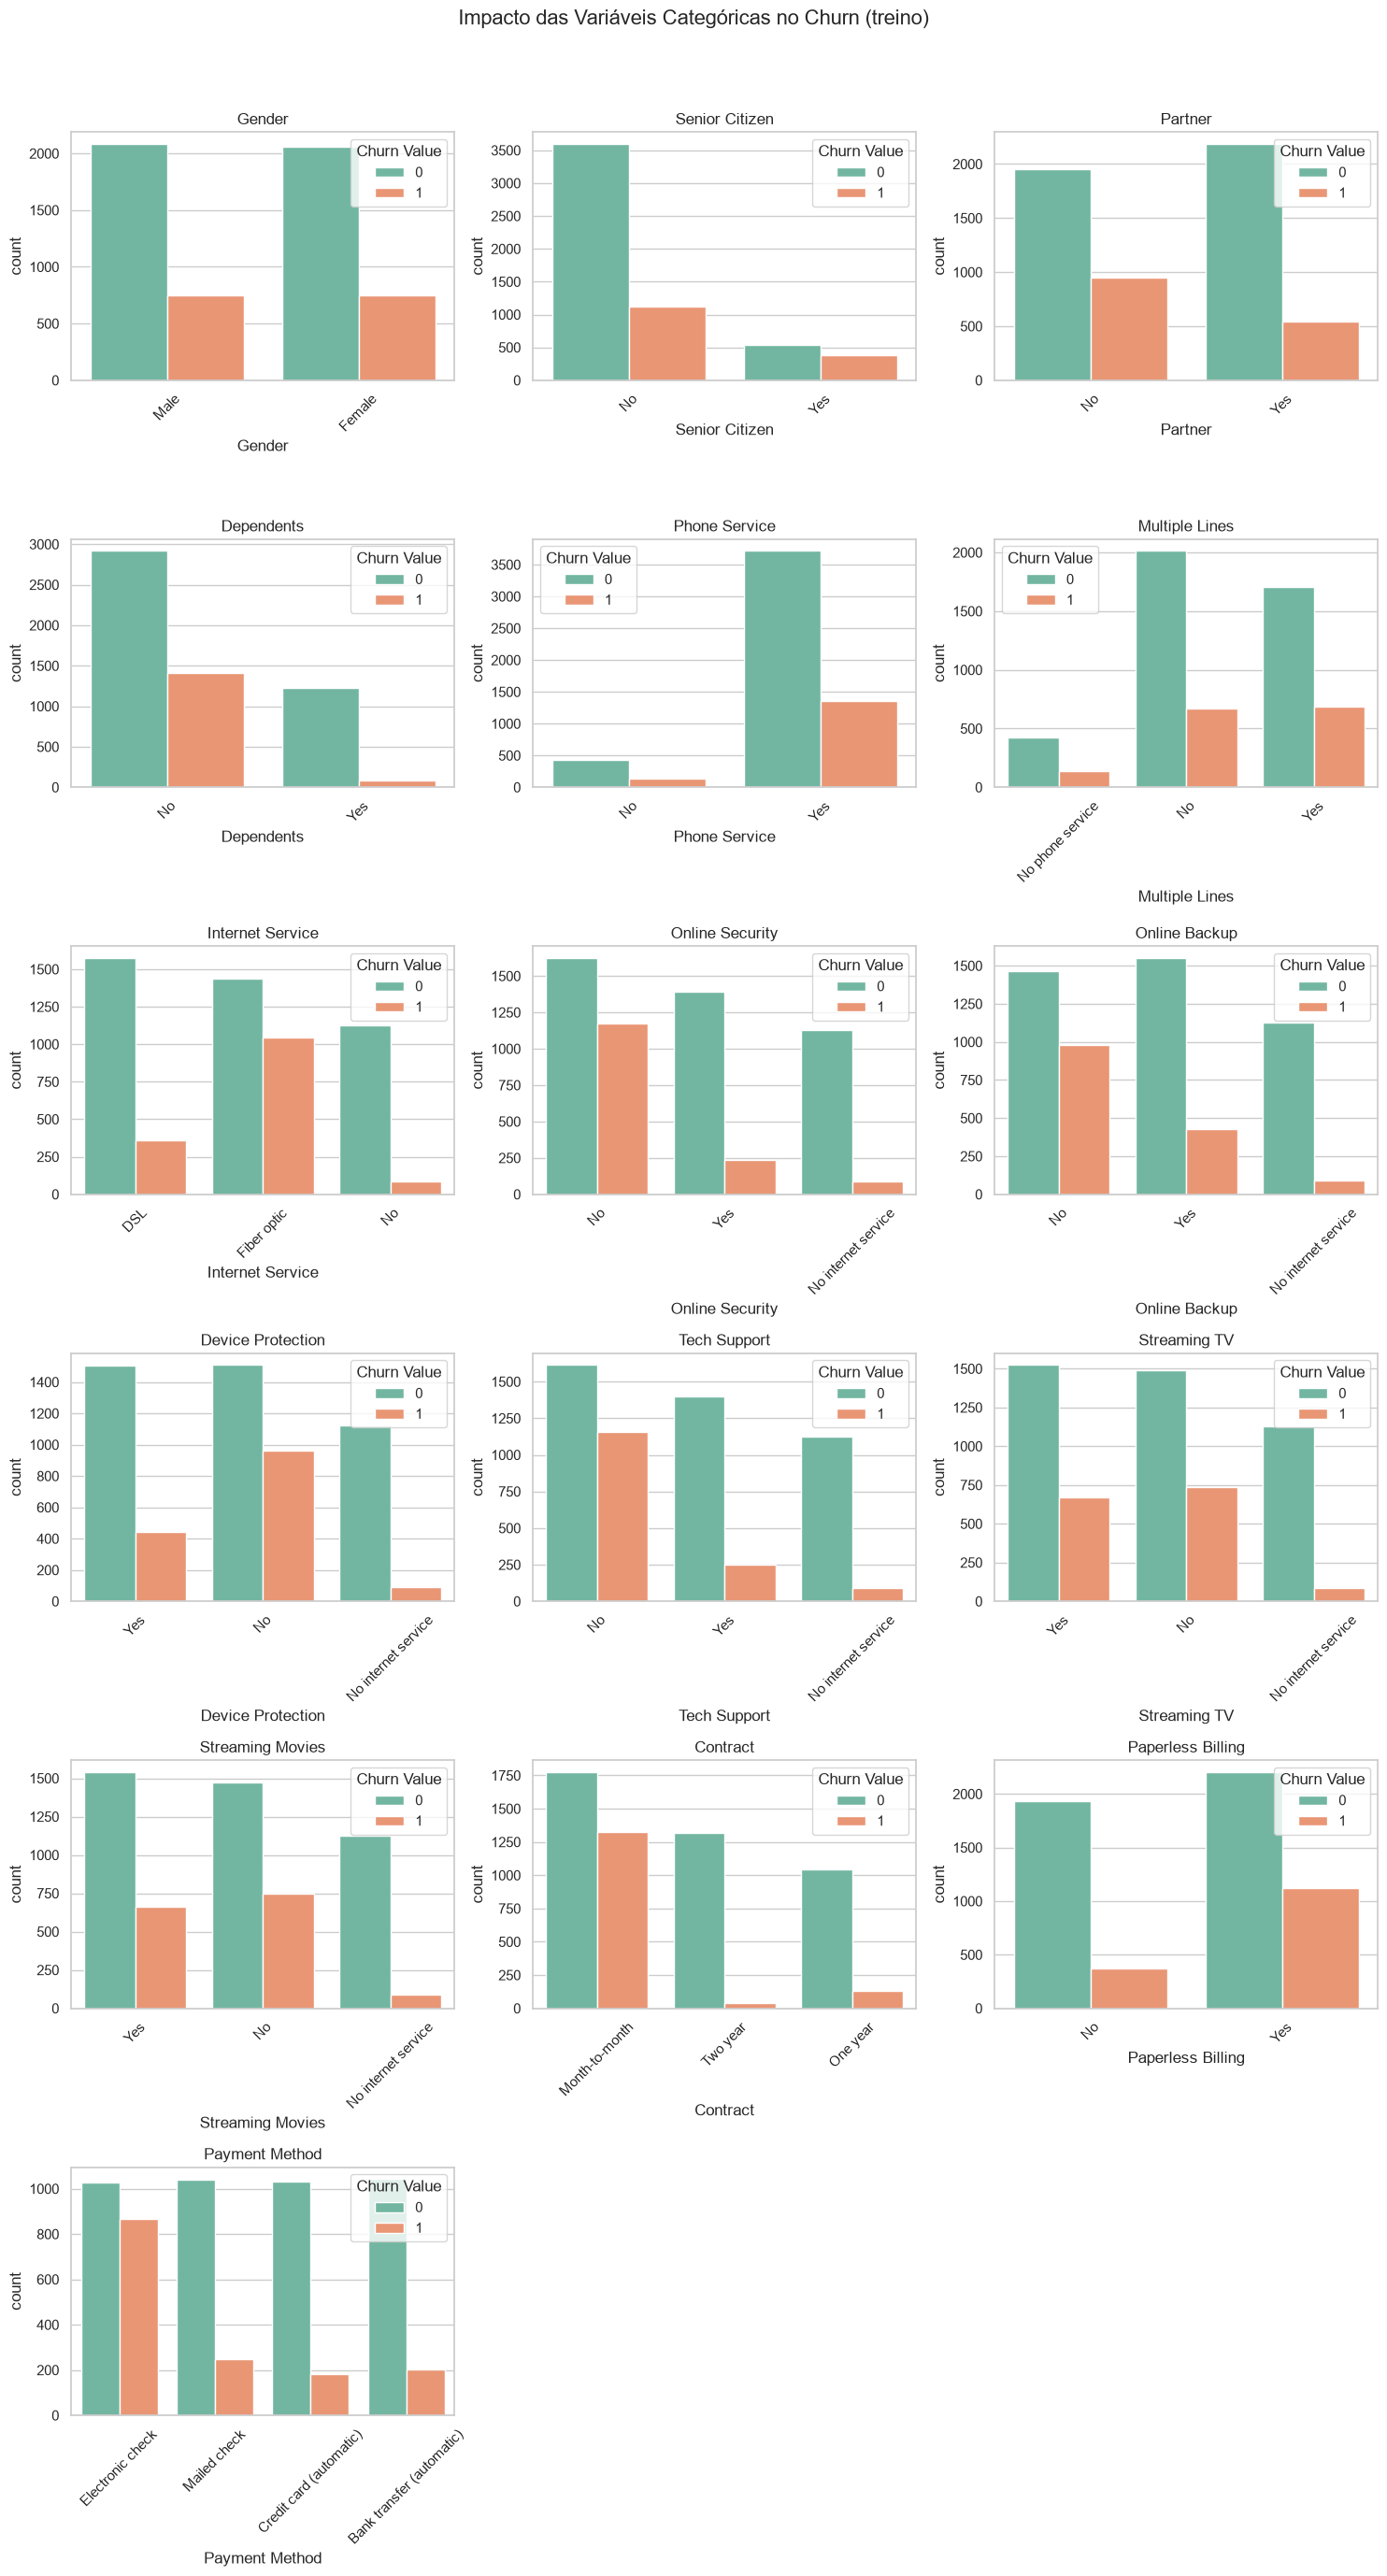


--- CORRELAÇÃO (treino) ---


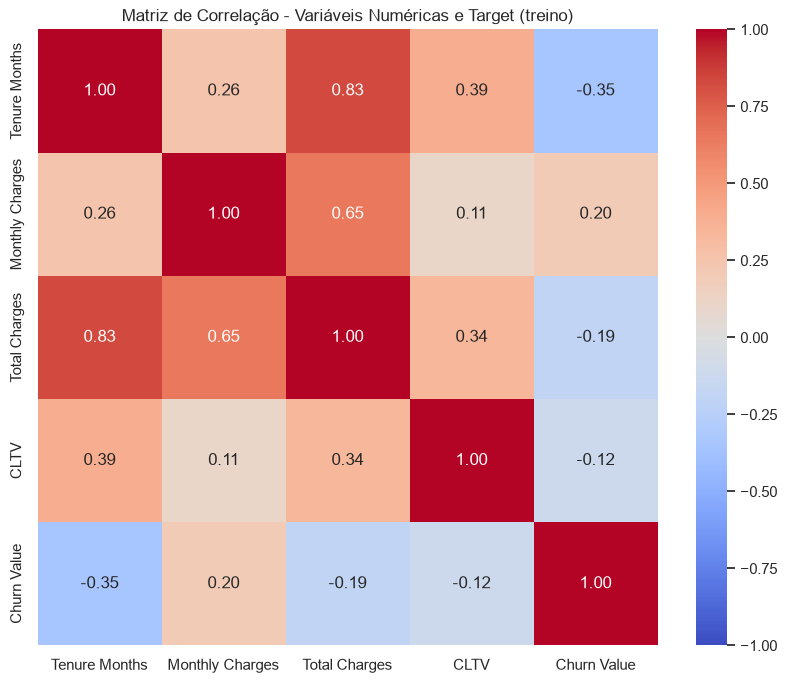

In [25]:
print("\n--- ANÁLISE BIVARIADA (treino) ---")

# Variáveis numéricas vs target
plot_dynamic_grid(train_df, num_features, target_col, 'box_bivariate', 'Variáveis Numéricas em Relação ao Churn (treino)')

# Variáveis categóricas vs target
plot_dynamic_grid(train_df, cat_features, target_col, 'count_bivariate', 'Impacto das Variáveis Categóricas no Churn (treino)')


print("\n--- CORRELAÇÃO (treino) ---")

# Matriz de correlação entre as numéricas e o target
if num_features:
    plt.figure(figsize=(10, 8))
    corr = train_df[num_features + [target_col]].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Matriz de Correlação - Variáveis Numéricas e Target (treino)')
    plt.show()

In [26]:
def woe_iv_table(x: pd.Series, y: pd.Series, n_bins: int = 10, eps: float = 0.5) -> pd.DataFrame:
    """Tabela de WOE/IV de uma variável. WOE = ln(%churn / %não-churn); > 0 indica faixa de maior risco."""
    # Numéricas com muitos valores: discretiza em quantis (bins duplicados são descartados)
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > n_bins:
        x = pd.qcut(x, q=n_bins, duplicates="drop")
    x = x.astype(str)  # NaN vira categoria própria ("nan")

    tab = pd.crosstab(x, y).reindex(columns=[0, 1], fill_value=0)
    # eps evita log(0) em faixas sem churn (ou sem não-churn)
    pct_ev = (tab[1] + eps) / (tab[1].sum() + eps * len(tab))
    pct_nev = (tab[0] + eps) / (tab[0].sum() + eps * len(tab))

    out = pd.DataFrame({
        "Faixa": tab.index,
        "Clientes": tab.sum(axis=1).values,
        "Taxa de churn": (tab[1] / tab.sum(axis=1)).values,
        "WOE": np.log(pct_ev / pct_nev).values,
        "IV parcial": ((pct_ev - pct_nev) * np.log(pct_ev / pct_nev)).values,
    })
    return out


def iv_summary(X: pd.DataFrame, y: pd.Series, features: list[str], n_bins: int = 10) -> pd.DataFrame:
    rows = [{"Variável": f, "IV": woe_iv_table(X[f], y, n_bins)["IV parcial"].sum()} for f in features]
    res = pd.DataFrame(rows).sort_values("IV", ascending=False).reset_index(drop=True)
    res["Poder preditivo"] = pd.cut(
        res["IV"],
        bins=[-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
        labels=["inútil (<0,02)", "fraco", "médio", "forte", "suspeito (>0,5): checar leakage"],
    )
    return res


iv_table = iv_summary(X_train, y_train, num_features + cat_features)
iv_table

,Variável,IV,Poder preditivo
0,Contract,1.235678,"suspeito (>0,5): checar leakage"
1,Tenure Months,0.780222,"suspeito (>0,5): checar leakage"
2,Online Security,0.732530,"suspeito (>0,5): checar leakage"
3,Tech Support,0.707562,"suspeito (>0,5): checar leakage"
4,Internet Service,0.632767,"suspeito (>0,5): checar leakage"
5,Online Backup,0.535708,"suspeito (>0,5): checar leakage"
6,Device Protection,0.497168,forte
7,Dependents,0.486804,forte
8,Payment Method,0.480648,forte
9,Streaming Movies,0.385200,forte


In [27]:
woe_iv_table(X_train["Online Security"], y_train)

,Faixa,Clientes,Taxa de churn,WOE,IV parcial
0,No,2797,0.419378,0.692478,0.271326
1,No internet service,1214,0.072488,-1.526181,0.324971
2,Yes,1623,0.144177,-0.761556,0.136234


#### 7. Feature Selection

In [28]:
from scipy.stats import chi2_contingency


def cramers_v(a: pd.Series, b: pd.Series) -> float:
    """Cramér's V com correção de viés (0 = independentes, 1 = associação perfeita)."""
    ct = pd.crosstab(a, b)
    n = ct.values.sum()
    chi2 = chi2_contingency(ct, correction=False)[0]
    r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    denom = min(k_c - 1, r_c - 1)
    return float(np.sqrt(phi2 / denom)) if denom > 0 else 0.0


def cramers_v_matrix(X: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    m = pd.DataFrame(np.eye(len(features)), index=features, columns=features)
    for i, a in enumerate(features):
        for b in features[i + 1:]:
            m.loc[a, b] = m.loc[b, a] = cramers_v(X[a], X[b])
    return m


def drop_by_association(assoc: pd.DataFrame, iv: pd.Series, threshold: float = 0.8):
    """Para cada par com associação >= threshold, descarta a variável de menor IV.
    Retorna (lista de colunas a remover, log das decisões)."""
    upper = assoc.where(np.triu(np.ones(assoc.shape, dtype=bool), k=1))
    pairs = upper.stack().sort_values(ascending=False)

    dropped, log = [], []
    for (a, b), val in pairs.items():
        if val < threshold:
            break
        if a in dropped or b in dropped:   # par já resolvido por uma remoção anterior
            continue
        drop, keep = (a, b) if iv[a] < iv[b] else (b, a)
        dropped.append(drop)
        log.append({"Par": f"{a} x {b}", "Associação": round(val, 3),
                    "Removida": drop, "IV removida": round(iv[drop], 4),
                    "Mantida": keep, "IV mantida": round(iv[keep], 4)})
    return dropped, pd.DataFrame(log)

In [29]:
# Remoção de variáveis com alta colinearidade 
iv = iv_table.set_index("Variável")["IV"]

# Numéricas: |Spearman| (robusto à assimetria de Total Charges)
num_assoc = X_train[num_features].corr(method="spearman").abs()
drop_num, log_num = drop_by_association(num_assoc, iv, threshold=0.80)

# Categóricas: Cramér's V
cat_assoc = cramers_v_matrix(X_train, cat_features)
drop_cat, log_cat = drop_by_association(cat_assoc, iv, threshold=0.80)

cols_collinear = drop_num + drop_cat
print("Removidas por colinearidade:", cols_collinear)
display(log_num); display(log_cat)

# Aplica a MESMA lista nos dois conjuntos (nada é recalculado no teste)
X_train_sel = X_train.drop(columns=cols_collinear)
X_test_sel = X_test.drop(columns=cols_collinear)

Removidas por colinearidade: ['Total Charges', 'Phone Service']


,Par,Associação,Removida,IV removida,Mantida,IV mantida
0,Tenure Months x Total Charges,0.892,Total Charges,0.3039,Tenure Months,0.7802


,Par,Associação,Removida,IV removida,Mantida,IV mantida
0,Phone Service x Multiple Lines,1.0,Phone Service,0.0016,Multiple Lines,0.0099


In [30]:
X_train_sel.dtypes

Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
CLTV                   int64
dtype: object

#### 8. Pré-processamento

In [42]:
X_tr, X_te = X_train_sel, X_test_sel

num_cols = X_tr.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_tr.select_dtypes(exclude=[np.number]).columns.tolist()


def build_preprocessor(num_cols: list[str], cat_cols: list[str], scale_numeric: bool = True) -> ColumnTransformer:
    """Codifica categóricas e (opcionalmente) escala numéricas."""

    num_transformer = Pipeline([("scaler", StandardScaler())]) if scale_numeric else "passthrough"
    cat_pipe = Pipeline([
        ("onehot", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(
        [("num", num_transformer, num_cols),
         ("cat", cat_pipe, cat_cols)],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

#### 9. Modelagem

In [43]:
PROJECT_ROOT = Path("..").resolve()
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"

##### 9.1 Baseline

2026/11/03 16:21:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/03 16:21:33 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


--- RESULTADOS DO BASELINE TÉCNICO ---
ROC-AUC: 0.8465
PR-AUC (Average Precision): 0.6412

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.77      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



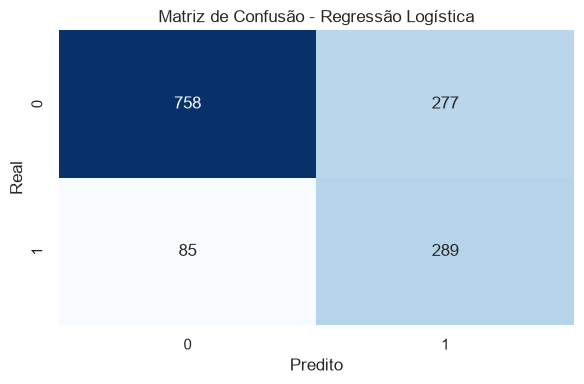

In [51]:
mlflow.set_experiment("Telco_Churn_Baseline")

baseline_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(num_cols, cat_cols, scale_numeric=True)),
    ("classifier", LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced"))
])

with mlflow.start_run(run_name="Logistic_Regression_Baseline"):
    
    # 1. Treinamento
    baseline_pipeline.fit(X_tr, y_train)
    
    # 2. Predições
    y_train_pred_baseline = baseline_pipeline.predict(X_tr)
    y_train_proba_baseline = baseline_pipeline.predict_proba(X_tr)[:, 1]
    y_test_pred_baseline = baseline_pipeline.predict(X_te)
    y_test_proba_baseline = baseline_pipeline.predict_proba(X_te)[:, 1]
    
    # 3. Métricas - teste
    auc_roc = roc_auc_score(y_test, y_test_proba_baseline)
    pr_auc = average_precision_score(y_test, y_test_proba_baseline) # <-- Cálculo do PR-AUC
    
    # 4. Log de Parâmetros e Métricas no MLflow
    mlflow.log_param("model", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("scale_numeric", True)
    
    mlflow.log_metric("roc_auc", auc_roc)
    mlflow.log_metric("pr_auc", pr_auc) # <-- Registo no MLflow
    
    # 5. Log do Modelo Completo
    mlflow.sklearn.log_model(baseline_pipeline, "baseline_pipeline_model")
    
    # 6. Exibição no Notebook
    print("--- RESULTADOS DO BASELINE TÉCNICO ---")
    print(f"ROC-AUC: {auc_roc:.4f}")
    print(f"PR-AUC (Average Precision): {pr_auc:.4f}\n") # <-- Exibição
    print("Relatório de Classificação:")
    print(classification_report(y_test, y_test_pred_baseline))
    
    # 7. Geração e Log de Artefato Gráfico (Matriz de Confusão)
    cm = confusion_matrix(y_test, y_test_pred_baseline)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Matriz de Confusão - Regressão Logística')
    plt.ylabel('Real')
    plt.xlabel('Predito')
    plt.tight_layout()
    
    cm_path = "confusion_matrix_baseline.png"
    plt.savefig(cm_path)
    mlflow.log_artifact(cm_path)
    plt.show()

##### 9.2 Cross validation

In [45]:
# Configuração da Validação Cruzada Estratificada no conjunto de treino
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Dicionário de pipelines candidatos
candidate_pipelines = {
    "Logistic_Regression": Pipeline([
        ("preprocessor", build_preprocessor(num_cols, cat_cols, scale_numeric=True)),
        ("classifier", LogisticRegression(
            random_state=RANDOM_STATE,
            max_iter=1000,
            class_weight="balanced"
        )),
    ]),
    "Random_Forest": Pipeline([
        ("preprocessor", build_preprocessor(num_cols, cat_cols, scale_numeric=False)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )),
    ]),
    "MLP_Classifier": Pipeline([
        ("preprocessor", build_preprocessor(num_cols, cat_cols, scale_numeric=True)),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=1e-3,
            batch_size=64,
            learning_rate_init=1e-3,
            max_iter=500,
            early_stopping=True,
            n_iter_no_change=15,
            random_state=RANDOM_STATE
        )),
    ]),
}

scoring_metrics = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
    "accuracy": "accuracy",
}

cv_summary_rows = []
cv_raw_results = {}

print("Executando Validação Cruzada Estratificada (5 folds) no conjunto de treino...")
for name, pipe in candidate_pipelines.items():
    scores = cross_validate(
        pipe,
        X_tr,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=True,
    )
    cv_raw_results[name] = scores
    cv_summary_rows.append({
        "Modelo": name,
        "CV ROC-AUC (Mean ± Std)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "CV PR-AUC (Mean ± Std)": f"{scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}",
        "CV F1 (Mean ± Std)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        "CV Recall (Mean)": round(scores["test_recall"].mean(), 4),
        "CV Precision (Mean)": round(scores["test_precision"].mean(), 4),
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "Train ROC-AUC Mean": scores["train_roc_auc"].mean(),
    })

cv_results_df = pd.DataFrame(cv_summary_rows).sort_values(by="CV ROC-AUC Mean", ascending=False).reset_index(drop=True)
display(cv_results_df.drop(columns=["CV ROC-AUC Mean"]))

Executando Validação Cruzada Estratificada (5 folds) no conjunto de treino...


,Modelo,CV ROC-AUC (Mean ± Std),CV PR-AUC (Mean ± Std),CV F1 (Mean ± Std),CV Recall (Mean),CV Precision (Mean),Train ROC-AUC Mean
0,Random_Forest,0.8588 ± 0.0080,0.6717 ± 0.0211,0.6533 ± 0.0151,0.7639,0.5711,0.925549
1,MLP_Classifier,0.8584 ± 0.0112,0.6734 ± 0.0250,0.6048 ± 0.0255,0.5431,0.6842,0.872185
2,Logistic_Regression,0.8580 ± 0.0123,0.6786 ± 0.0198,0.6396 ± 0.0196,0.8013,0.5326,0.861456


#### 10. Otimização


In [46]:
def objective(trial):
    # 1. O Optuna escolhe dinamicamente qual classificador testar nesta iteração
    classifier_name = trial.suggest_categorical("classifier", ["RandomForest", "MLP", "LogisticRegression"])
    
    # 2. Definição do espaço de hiperparâmetros com base no classificador escolhido
    if classifier_name == "RandomForest":
        n_estimators = trial.suggest_int("n_estimators", 100, 500, step=100)
        max_depth = trial.suggest_int("max_depth", 5, 20)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
        # Nomes diferentes para evitar conflito com os parâmetros da regressão logística
        class_weight = trial.suggest_categorical("rf_class_weight", ["balanced", "balanced_subsample", None])
        
        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            class_weight=class_weight,
            random_state=RANDOM_STATE
        )
        
    elif classifier_name == "MLP":
        # Mapeando tuplas usando strings, pois o Optuna lida melhor com strings em categorias
        layer_choice = trial.suggest_categorical("hidden_layer_sizes", ["50", "100", "50_50", "100_50"])
        if layer_choice == "50":
            hidden_layer_sizes = (50,)
        elif layer_choice == "100":
            hidden_layer_sizes = (100,)
        elif layer_choice == "50_50":
            hidden_layer_sizes = (50, 50)
        else:
            hidden_layer_sizes = (100, 50)
            
        activation = trial.suggest_categorical("activation", ["tanh", "relu"])
        alpha = trial.suggest_float("alpha", 1e-4, 1e-1, log=True)
        learning_rate_init = trial.suggest_float("learning_rate_init", 1e-3, 5e-1, log=True)
        
        model = MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            activation=activation,
            alpha=alpha,
            learning_rate_init=learning_rate_init,
            max_iter=1000,
            early_stopping=True,
            random_state=RANDOM_STATE
        )
        
    else: # LogisticRegression
        c_val = trial.suggest_float("C", 1e-2, 1e2, log=True)
        solver = trial.suggest_categorical("solver", ["liblinear", "lbfgs"])
        class_weight = trial.suggest_categorical("lr_class_weight", ["balanced", None])
        
        model = LogisticRegression(
            C=c_val,
            solver=solver,
            class_weight=class_weight,
            max_iter=2000,
            random_state=RANDOM_STATE
        )

    # 3. Construção do Pipeline (agora apenas com Scikit-Learn, sem undersampling)
    preprocessor = build_preprocessor(num_cols, cat_cols, scale_numeric=True)
    
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # 4. Validação Cruzada Estratificada
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    
    # 5. Calculando as múltiplas métricas
    scores = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=cv, 
        scoring=["roc_auc", "f1"], 
        n_jobs=-1,
        error_score="raise" # Útil para alertar se houver algum erro de convergência (ex: no MLP)
    )
    
    auc_mean = scores["test_roc_auc"].mean()
    f1_mean = scores["test_f1"].mean()
    
    # Retorna na ordem definida no 'directions' do create_study
    return auc_mean, f1_mean

# ---------------------------------------------------------
# Execução do Estudo Optuna
# ---------------------------------------------------------

print("Iniciando Otimização Multiobjetivo com Optuna (RF, MLP e LogReg)...")

# directions=['maximize', 'maximize'] indica a maximização de AUC (1º) e F1 (2º)
study = optuna.create_study(directions=["maximize", "maximize"], study_name="Churn_Models_Optimization")

# n_trials dita quantas tentativas o Optuna vai fazer no total (sugerido: 50 a 100)
study.optimize(objective, n_trials=50)

# ---------------------------------------------------------
# Análise dos Resultados (Fronteira de Pareto)
# ---------------------------------------------------------

print("\n--- MELHORES MODELOS ENCONTRADOS (PARETO FRONT) ---")
best_trials = study.best_trials

pareto_results = []
for trial in best_trials:
    pareto_results.append({
        "Trial": trial.number,
        "Algorithm": trial.params.get("classifier"),
        "ROC-AUC": trial.values[0],
        "F1-Score": trial.values[1],
        "Params": trial.params
    })

pareto_df = pd.DataFrame(pareto_results).sort_values(by="F1-Score", ascending=False)
display(pareto_df)

[I 2026-11-03 15:59:37,805] A new study created in memory with name: Churn_Models_Optimization


Iniciando Otimização Multiobjetivo com Optuna (RF, MLP e LogReg)...


[I 2026-11-03 15:59:38,560] Trial 0 finished with values: [0.8579970462735049, 0.6477070485606671] and parameters: {'classifier': 'RandomForest', 'n_estimators': 300, 'max_depth': 10, 'min_samples_split': 7, 'min_samples_leaf': 2, 'rf_class_weight': 'balanced'}.
[I 2026-11-03 15:59:38,767] Trial 1 finished with values: [0.8565718089636732, 0.5793424009418988] and parameters: {'classifier': 'RandomForest', 'n_estimators': 100, 'max_depth': 6, 'min_samples_split': 4, 'min_samples_leaf': 4, 'rf_class_weight': None}.
[I 2026-11-03 15:59:39,306] Trial 2 finished with values: [0.8571752531688116, 0.6498103189294605] and parameters: {'classifier': 'RandomForest', 'n_estimators': 200, 'max_depth': 16, 'min_samples_split': 11, 'min_samples_leaf': 5, 'rf_class_weight': 'balanced'}.
[I 2026-11-03 15:59:39,380] Trial 3 finished with values: [0.8580212650411949, 0.6161585029066956] and parameters: {'classifier': 'LogisticRegression', 'C': 1.8592408589915064, 'solver': 'liblinear', 'lr_class_weight'


--- MELHORES MODELOS ENCONTRADOS (PARETO FRONT) ---


,Trial,Algorithm,ROC-AUC,F1-Score,Params
0,10,RandomForest,0.859186,0.652659,"{'classifier': 'RandomForest', 'n_estimators':..."
1,11,RandomForest,0.859186,0.652659,"{'classifier': 'RandomForest', 'n_estimators':..."
2,12,RandomForest,0.859186,0.652659,"{'classifier': 'RandomForest', 'n_estimators':..."
3,13,RandomForest,0.859186,0.652659,"{'classifier': 'RandomForest', 'n_estimators':..."
4,21,RandomForest,0.859186,0.652659,"{'classifier': 'RandomForest', 'n_estimators':..."
7,37,RandomForest,0.859187,0.650900,"{'classifier': 'RandomForest', 'n_estimators':..."
8,42,RandomForest,0.859187,0.650900,"{'classifier': 'RandomForest', 'n_estimators':..."
5,30,RandomForest,0.859204,0.650893,"{'classifier': 'RandomForest', 'n_estimators':..."
6,31,RandomForest,0.859204,0.650893,"{'classifier': 'RandomForest', 'n_estimators':..."
9,48,RandomForest,0.859613,0.650496,"{'classifier': 'RandomForest', 'n_estimators':..."


In [47]:
# =====================================================================
# SELEÇÃO E TREINAMENTO DO MODELO CAMPEÃO (CHAMPION PIPELINE)
# =====================================================================
# Ordena os melhores trials pelo ROC-AUC (índice 0) e seleciona o melhor
best_trial = sorted(study.best_trials, key=lambda t: t.values[0], reverse=True)[0]
best_params = best_trial.params

print(f"Instanciando o Campeão: {best_params['classifier']}...")

# 1. Recria o classificador com os melhores hiperparâmetros extraídos
if best_params['classifier'] == "RandomForest":
    champion_model = RandomForestClassifier(
        n_estimators=best_params['n_estimators'],
        max_depth=best_params['max_depth'],
        min_samples_split=best_params['min_samples_split'],
        min_samples_leaf=best_params['min_samples_leaf'],
        class_weight=best_params['rf_class_weight'],
        random_state=RANDOM_STATE
    )
elif best_params['classifier'] == "MLP":
    layer_choice = best_params['hidden_layer_sizes']
    if layer_choice == "50":
        hidden_layer_sizes = (50,)
    elif layer_choice == "100":
        hidden_layer_sizes = (100,)
    elif layer_choice == "50_50":
        hidden_layer_sizes = (50, 50)
    else:
        hidden_layer_sizes = (100, 50)
        
    champion_model = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=best_params['activation'],
        alpha=best_params['alpha'],
        learning_rate_init=best_params['learning_rate_init'],
        max_iter=1000,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
else: # LogisticRegression
    champion_model = LogisticRegression(
        C=best_params['C'],
        solver=best_params['solver'],
        class_weight=best_params['lr_class_weight'],
        max_iter=2000,
        random_state=RANDOM_STATE
    )

# 2. Constrói o pipeline final acoplando o pré-processador
# Atenção: as variáveis de lista precisam estar com o nome correto do seu notebook (num_features, cat_features)
preprocessor = build_preprocessor(num_features, cat_features, scale_numeric=True)

champion_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', champion_model)
])

# 3. Treina o pipeline campeão com todos os dados de treino
print("Treinando o pipeline final campeão...")
champion_pipeline.fit(X_train, y_train)

# Variável para o título dos gráficos
champion_name = best_params['classifier']
print("Pronto! champion_pipeline instanciado e treinado com sucesso.")

Instanciando o Campeão: RandomForest...
Treinando o pipeline final campeão...
Pronto! champion_pipeline instanciado e treinado com sucesso.


#### 11. Avaliação Gráfica: Curva ROC e Precision-Recall
Comparativo direto do nosso Campeão Selecionado contra o Baseline de Negócio (Churn Score).


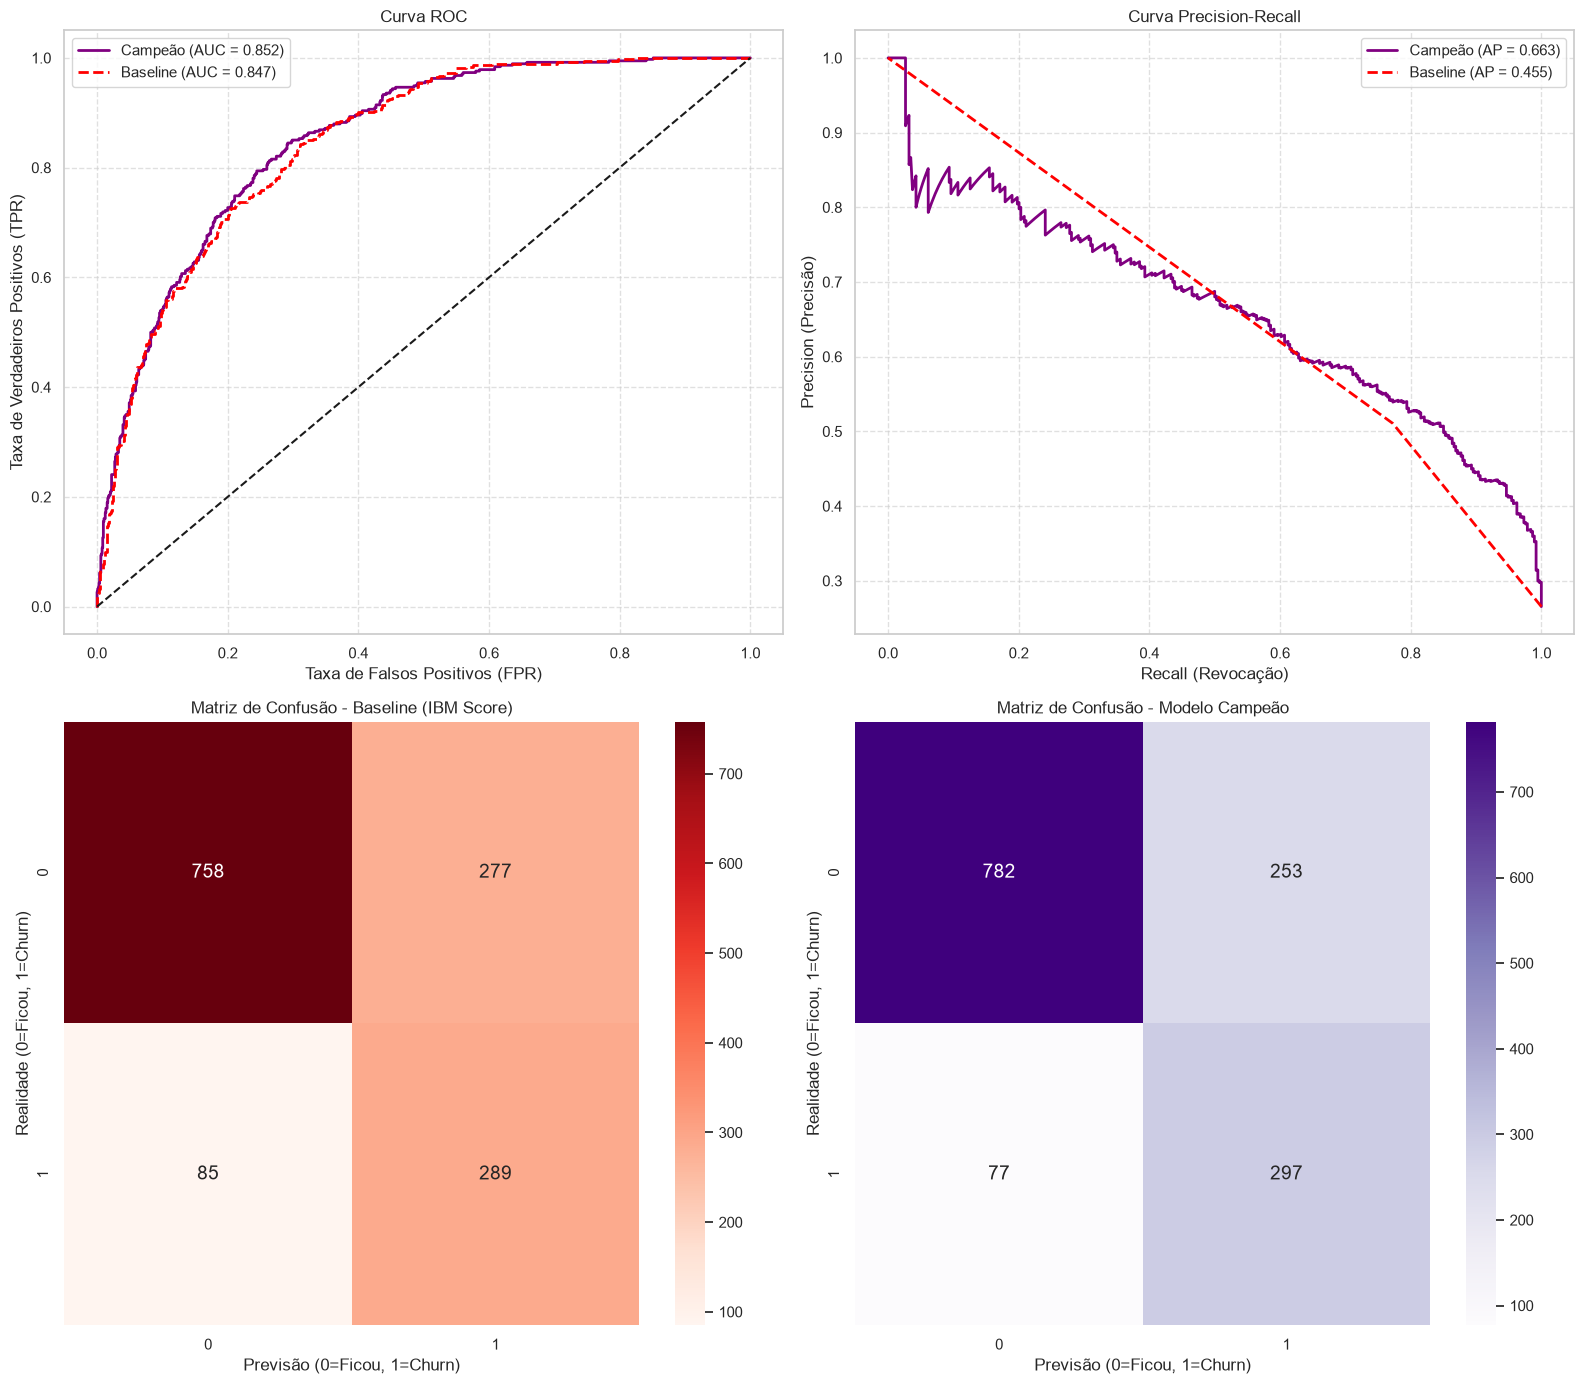


--- RESUMO DE MÉTRICAS COMPARATIVAS ---


,Métrica,Baseline,Modelo Campeão
0,ROC-AUC,0.846503,0.852136
1,PR-AUC (Average Precision),0.454882,0.662837
2,F1-Score,0.614894,0.642857
3,Acurácia,0.743080,0.765791
4,Recall (Captura Real),0.772727,0.794118
5,Precision (Assertividade),0.510601,0.540000


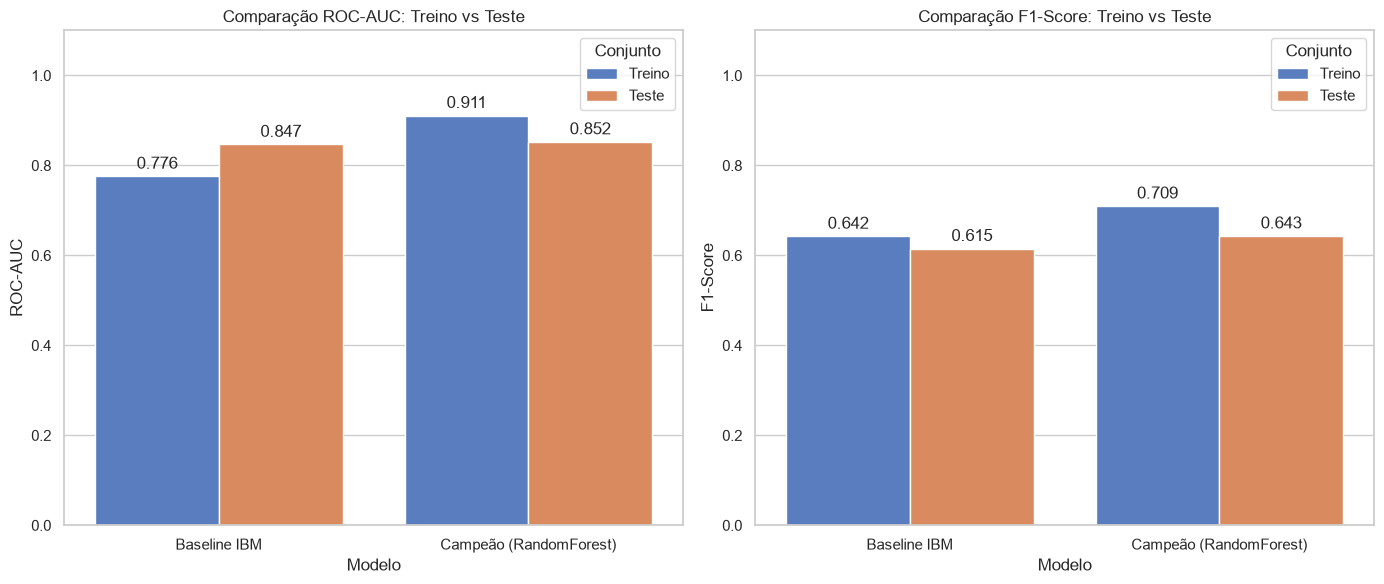


--- IMPACTO DE NEGÓCIO: TAXAS DE CHURN ---
Total de Clientes no Teste: 1409
Churn Real (Sem modelo preditivo): 374 clientes perdidos (Taxa: 26.5%)
------------------------------------------------------------
COMPORTAMENTO DO BASELINE (IBM Score >= 50):
 - Alarmes disparados (Risco de Churn apontado): 566
 - Churns reais capturados (Verdadeiros Positivos): 289
 - Taxa de Captura do Churn (Recall): 77.3%
 - Alarmes Falsos (Falsos Positivos gastos): 277
------------------------------------------------------------
COMPORTAMENTO DO MODELO CAMPEÃO OTIMIZADO:
 - Alarmes disparados (Risco de Churn apontado): 550
 - Churns reais capturados (Verdadeiros Positivos): 297
 - Taxa de Captura do Churn (Recall): 79.4%
 - Alarmes Falsos (Falsos Positivos gastos): 253
------------------------------------------------------------


In [ ]:
# Gerando predições do modelo campeão
y_pred_prob_champ = champion_pipeline.predict_proba(X_test)[:, 1]
y_pred_champ = champion_pipeline.predict(X_test)



# =====================================================================
# 1. GRÁFICOS DE COMPARAÇÃO E RESUMO DE MÉTRICAS
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1.1 Curva ROC
fpr_c, tpr_c, _ = roc_curve(y_test, y_pred_prob_champ)
auc_c = roc_auc_score(y_test, y_pred_prob_champ)
fpr_b, tpr_b, _ = roc_curve(y_test, y_test_proba_baseline)
auc_b = roc_auc_score(y_test, y_test_proba_baseline)

axes[0, 0].plot(fpr_c, tpr_c, label=f"Campeão (AUC = {auc_c:.3f})", color='purple', lw=2)
axes[0, 0].plot(fpr_b, tpr_b, label=f"Baseline (AUC = {auc_b:.3f})", color='red', ls='--', lw=2)
axes[0, 0].plot([0, 1], [0, 1], 'k--')
axes[0, 0].set_title('Curva ROC')
axes[0, 0].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[0, 0].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# 1.2 Curva Precision-Recall (PR-AUC)
prec_c, rec_c, _ = precision_recall_curve(y_test, y_pred_prob_champ)
ap_c = average_precision_score(y_test, y_pred_prob_champ)
prec_b, rec_b, _ = precision_recall_curve(y_test, y_test_pred_baseline)
ap_b = average_precision_score(y_test, y_test_pred_baseline)

axes[0, 1].plot(rec_c, prec_c, label=f"Campeão (AP = {ap_c:.3f})", color='purple', lw=2)
axes[0, 1].plot(rec_b, prec_b, label=f"Baseline (AP = {ap_b:.3f})", color='red', ls='--', lw=2)
axes[0, 1].set_title('Curva Precision-Recall')
axes[0, 1].set_xlabel('Recall (Revocação)')
axes[0, 1].set_ylabel('Precision (Precisão)')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# 1.3 Matriz de Confusão - Baseline
cm_b = confusion_matrix(y_test, y_test_pred_baseline)
sns.heatmap(cm_b, annot=True, fmt='d', cmap='Reds', ax=axes[1, 0], annot_kws={"size": 14})
axes[1, 0].set_title('Matriz de Confusão - Baseline (IBM Score)')
axes[1, 0].set_ylabel('Realidade (0=Ficou, 1=Churn)')
axes[1, 0].set_xlabel('Previsão (0=Ficou, 1=Churn)')

# 1.4 Matriz de Confusão - Campeão
cm_c = confusion_matrix(y_test, y_pred_champ)
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Purples', ax=axes[1, 1], annot_kws={"size": 14})
axes[1, 1].set_title('Matriz de Confusão - Modelo Campeão')
axes[1, 1].set_ylabel('Realidade (0=Ficou, 1=Churn)')
axes[1, 1].set_xlabel('Previsão (0=Ficou, 1=Churn)')

plt.tight_layout()
plt.show()

# Resumo em Tabela
metrics_summary = pd.DataFrame({
    'Métrica': ['ROC-AUC', 'PR-AUC (Average Precision)', 'F1-Score', 'Acurácia', 'Recall (Captura Real)', 'Precision (Assertividade)'],
    'Baseline': [
        auc_b, ap_b, 
        f1_score(y_test, y_test_pred_baseline), 
        accuracy_score(y_test, y_test_pred_baseline),
        recall_score(y_test, y_test_pred_baseline),
        precision_score(y_test, y_test_pred_baseline)
    ],
    'Modelo Campeão': [
        auc_c, ap_c, 
        f1_score(y_test, y_pred_champ), 
        accuracy_score(y_test, y_pred_champ),
        recall_score(y_test, y_pred_champ),
        precision_score(y_test, y_pred_champ)
    ]
})
print("\n--- RESUMO DE MÉTRICAS COMPARATIVAS ---")
display(metrics_summary)


# =====================================================================
# COMPARAÇÃO TREINO VS TESTE (Avaliação de Overfitting)
# =====================================================================
# Calculando predições do campeão no Treino
y_pred_prob_champ_train = champion_pipeline.predict_proba(X_train)[:, 1]
y_pred_champ_train = champion_pipeline.predict(X_train)

# Calculando métricas de Treino
auc_c_train = roc_auc_score(y_train, y_pred_prob_champ_train)
f1_c_train = f1_score(y_train, y_pred_champ_train)

auc_b_train = roc_auc_score(y_train, y_train_pred_baseline)
f1_b_train = f1_score(y_train, y_train_pred_baseline)

# Estruturando os dados para o gráfico
df_overfitting = pd.DataFrame({
    'Modelo': ['Baseline', 'Baseline', f'Campeão ({champion_name})', f'Campeão ({champion_name})'],
    'Conjunto': ['Treino', 'Teste', 'Treino', 'Teste'],
    'ROC-AUC': [auc_b_train, auc_b, auc_c_train, auc_c],
    'F1-Score': [f1_b_train, f1_score(y_test, y_test_pred_baseline), f1_c_train, f1_score(y_test, y_pred_champ)]
})

# Plotando os gráficos de barras comparativos
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico ROC-AUC
sns.barplot(data=df_overfitting, x='Modelo', y='ROC-AUC', hue='Conjunto', palette='muted', ax=axes[0])
axes[0].set_title('Comparação ROC-AUC: Treino vs Teste')
axes[0].set_ylim(0, 1.1)

# Gráfico F1-Score
sns.barplot(data=df_overfitting, x='Modelo', y='F1-Score', hue='Conjunto', palette='muted', ax=axes[1])
axes[1].set_title('Comparação F1-Score: Treino vs Teste')
axes[1].set_ylim(0, 1.1)

# Adicionando os rótulos numéricos no topo das barras
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3)

plt.tight_layout()
plt.show()

# =====================================================================
# 2. COMPARAÇÃO DAS TAXAS DE CHURN (Negócio)
# =====================================================================
total_clientes = len(y_test)
churn_real = y_test.sum()
taxa_churn_real = churn_real / total_clientes

churn_previsto_baseline = y_test_pred_baseline.sum()
churn_previsto_campeao = y_pred_champ.sum()

print("\n--- IMPACTO DE NEGÓCIO: TAXAS DE CHURN ---")
print(f"Total de Clientes no Teste: {total_clientes}")
print(f"Churn Real (Sem modelo preditivo): {churn_real} clientes perdidos (Taxa: {taxa_churn_real:.1%})")
print("-" * 60)
print("COMPORTAMENTO DO BASELINE (IBM Score >= 50):")
print(f" - Alarmes disparados (Risco de Churn apontado): {churn_previsto_baseline}")
print(f" - Churns reais capturados (Verdadeiros Positivos): {cm_b[1,1]}")
print(f" - Taxa de Captura do Churn (Recall): {cm_b[1,1] / churn_real:.1%}")
print(f" - Alarmes Falsos (Falsos Positivos gastos): {cm_b[0,1]}")
print("-" * 60)
print("COMPORTAMENTO DO MODELO CAMPEÃO OTIMIZADO:")
print(f" - Alarmes disparados (Risco de Churn apontado): {churn_previsto_campeao}")
print(f" - Churns reais capturados (Verdadeiros Positivos): {cm_c[1,1]}")
print(f" - Taxa de Captura do Churn (Recall): {cm_c[1,1] / churn_real:.1%}")
print(f" - Alarmes Falsos (Falsos Positivos gastos): {cm_c[0,1]}")
print("-" * 60)

#### 12. Salva modelo campeão
Exportando o pipeline para uso na Etapa 3 (FastAPI).


In [ ]:
model_path = Path('../models/campeao_otimizado.pkl')
model_path.parent.mkdir(parents=True, exist_ok=True)

# Salvando o pipeline completo (incluindo ColumnTransformer e Classificador)
joblib.dump(champion_pipeline, model_path)
print(f"\n✅ Pipeline do modelo final salvo com sucesso para Deploy em: {model_path.resolve()}")